# Project 1: VaR and ES -- Estimation, Backtesting, and Model Comparison

**Names of all group members:**
- Firstname Lastname (email@example.com)
- Firstname Lastname (email@example.com)

---

## 0) Setup

Creates necessary folders, sets parameters, and fixes the random seed. Keep this seed fixed; the whole run must be reproducible from it.

In [1]:
# If a package import fails, install it in your environment, e.g.:
# %pip install arch statsmodels

import os
import numpy as np
import pandas as pd
import scipy.stats as stats
import matplotlib.pyplot as plt
from pathlib import Path

PROJECT_DIR = Path.cwd()
DATA_FILE = PROJECT_DIR / "../data/QRM_2026_Project_prices.csv"   # provided with the project; do not re-download
OUT_DIR = PROJECT_DIR / "output"
OUT_DIR.mkdir(parents=True, exist_ok=True)

# Parameters
TICKERS = ["AAPL", "META", "JPM"]   # every question is run separately on each stock
WINDOW = 504                        # estimation window of every model, in trading days (Questions 2-5)
EVAL_START = 504                    # Questions 3-5: forecast days are all days after the first 504
REFIT = 21                          # Questions 4-5: re-estimate every this many trading days
ALPHAS = [0.975, 0.99]              # confidence levels used throughout Questions 2-5
DEEP_ALPHA = 0.999                  # Question 6: the extreme level EVT is asked for
M_SIM = 10_000                      # Questions 3(c), 4(d): Acerbi-Szekely simulated samples
LB_LAGS = 10                        # Ljung-Box H in Questions 1 and 4
NW_LAGS = 10                        # Newey-West truncation lag of the Diebold-Mariano test
SEED = 0                            # fix this, state it in the report, do not change it later

rng = np.random.default_rng(SEED)
print("Project dir:", PROJECT_DIR)


Project dir: /Users/meddeb/Documents/EPFL/MA3/QRM/QRM_Project/src


## 1) Data

The prices were downloaded once with `yfinance` (adjusted closes, 2 January 2013 to 30 June 2026,
downloaded on 28 October 2026) and are provided as `QRM_2026_Project_prices.csv`. Read this file;
do not download the data again, since Yahoo revises adjusted prices back in time.

In [2]:
price_df = pd.read_csv(DATA_FILE, index_col=0, parse_dates=True)[TICKERS]
print(price_df.shape, price_df.index[0].date(), "to", price_df.index[-1].date())   # (3393, 3)

(3393, 3) 2013-01-02 to 2026-06-30


## 2) Log-returns and losses

Construct $R_t=\log(P_t/P_{t-1})$ for each ticker. The log-loss used everywhere in this project is
$L_t=-R_t$. Every question is run separately on each of the three columns; there is no portfolio.

In [3]:
returns = np.log(price_df / price_df.shift(1)).dropna()
losses = -returns

print(returns.shape, returns.index[0].date(), "to", returns.index[-1].date())   # (3392, 3)
returns.head()

(3392, 3) 2013-01-03 to 2026-06-30


,AAPL,META,JPM
Date,,,
2013-01-03,-0.012703,-0.008248,-0.002017
2013-01-04,-0.028250,0.035029,0.017569
2013-01-07,-0.005900,0.022689,0.001101
2013-01-08,0.002688,-0.012312,0.001980
2013-01-09,-0.015752,0.051311,-0.000660


## Question 1 -- Stylized facts

For each stock: (a) plot the return series; (b) ACF of returns and of squared returns, and the
Ljung-Box test with $H$ = `LB_LAGS` on both (`statsmodels.stats.diagnostic.acorr_ljungbox`);
(c) QQ-plot and Jarque-Bera.

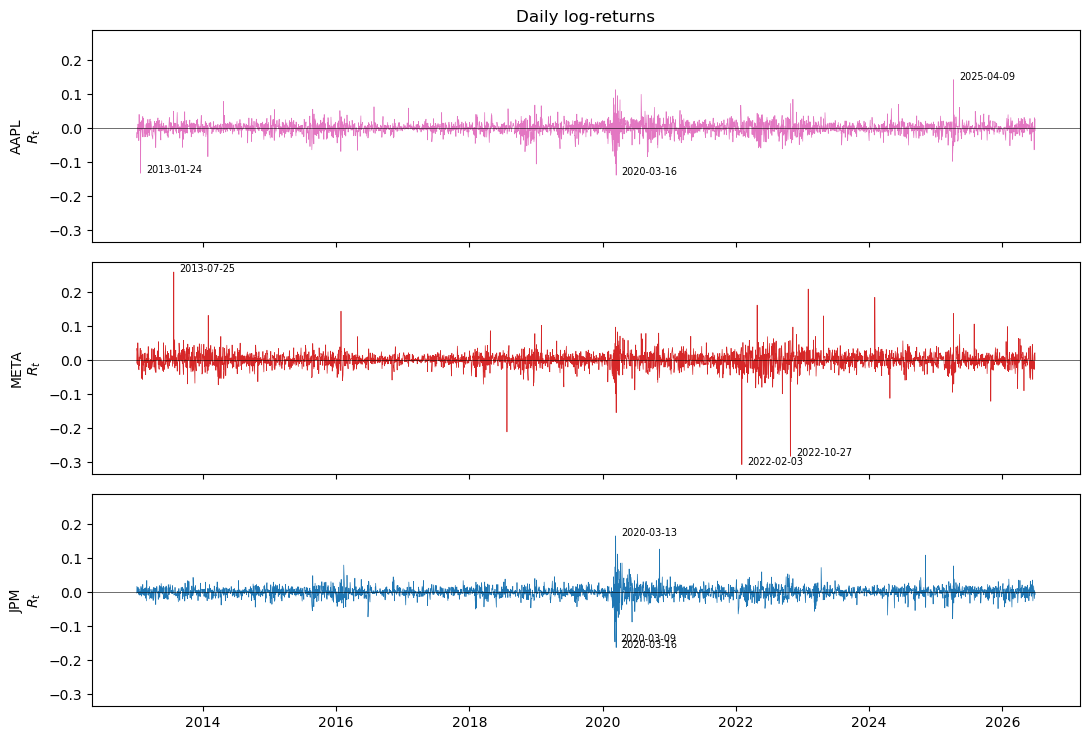

Correlation of 63-day rolling volatilities:
       AAPL  META   JPM
AAPL  1.00  0.60  0.77
META  0.60  1.00  0.47
JPM   0.77  0.47  1.00

Correlation of daily returns:
       AAPL  META   JPM
AAPL  1.00  0.46  0.39
META  0.46  1.00  0.31
JPM   0.39  0.31  1.00

Top-5 moves of AAPL (in %, all three stocks that day):
             AAPL   META    JPM
Date                           
2025-04-09  14.26  13.76   7.75
2020-03-16 -13.77 -15.38 -16.21
2013-01-24 -13.19   0.84   0.30
2020-03-13  11.32   9.74  16.56
2019-01-03 -10.49  -2.95  -1.43

Top-5 moves of META (in %, all three stocks that day):
            AAPL   META   JPM
Date                         
2022-02-03 -1.69 -30.64 -0.83
2022-10-27 -3.09 -28.18  0.39
2013-07-25 -0.46  25.94 -0.23
2018-07-26 -0.31 -21.02 -0.29
2023-02-02  3.64  20.93 -0.47

Top-5 moves of JPM (in %, all three stocks that day):
             AAPL   META    JPM
Date                           
2020-03-13  11.32   9.74  16.56
2020-03-16 -13.77 -15.38 -16.21
2020-03-09

In [4]:
# Question 1
# (a)
colors = {"AAPL": "tab:pink", "META": "tab:red", "JPM": "tab:blue"}


fig, axes = plt.subplots(3, 1, figsize=(11, 7.5), sharex=True, sharey=True)
for ax, tic in zip(axes, TICKERS):
    ax.plot(returns.index, returns[tic], lw=0.5, color=colors[tic])
    ax.axhline(0, color="black", lw=0.4)
    ax.set_ylabel(f"{tic}\n$R_t$")
    for d in returns[tic].abs().nlargest(3).index:          
        ax.annotate(d.strftime("%Y-%m-%d"), (d, returns.loc[d, tic]),
                    fontsize=7, xytext=(4, 0), textcoords="offset points")
axes[0].set_title("Daily log-returns")
plt.tight_layout()
plt.savefig(OUT_DIR / "fig_q1a_returns.png", dpi=200)
plt.show()

roll_vol = returns.rolling(63).std() * np.sqrt(252)         
print("Correlation of 63-day rolling volatilities:\n", roll_vol.corr().round(2))
print("\nCorrelation of daily returns:\n", returns.corr().round(2))
for tic in TICKERS:                                          
    top = returns[tic].abs().nlargest(5).index
    print(f"\nTop-5 moves of {tic} (in %, all three stocks that day):")
    print((100 * returns.loc[top]).round(2).to_string())

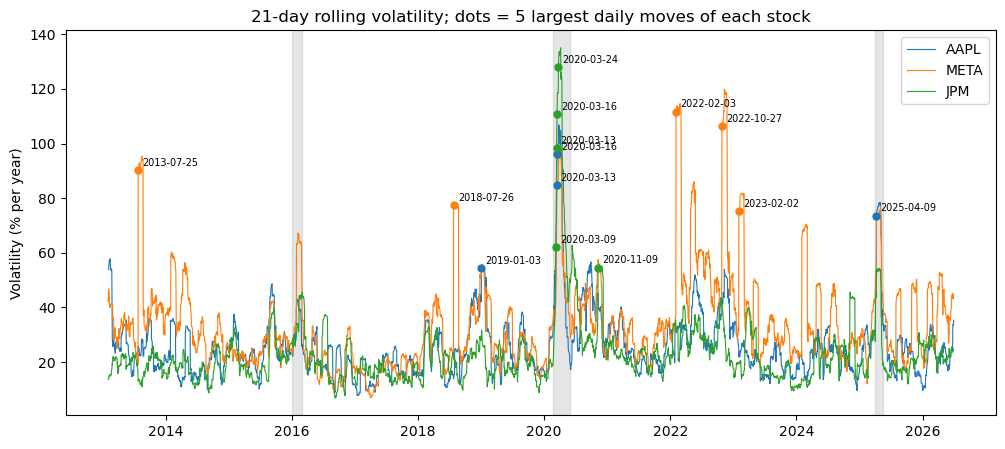


5 largest moves of AAPL (returns in %):
            AAPL  META   JPM
Date                        
2025-04-09  14.3  13.8   7.7
2020-03-16 -13.8 -15.4 -16.2
2013-01-24 -13.2   0.8   0.3
2020-03-13  11.3   9.7  16.6
2019-01-03 -10.5  -2.9  -1.4

5 largest moves of META (returns in %):
            AAPL  META  JPM
Date                       
2022-02-03  -1.7 -30.6 -0.8
2022-10-27  -3.1 -28.2  0.4
2013-07-25  -0.5  25.9 -0.2
2018-07-26  -0.3 -21.0 -0.3
2023-02-02   3.6  20.9 -0.5

5 largest moves of JPM (returns in %):
            AAPL  META   JPM
Date                        
2020-03-13  11.3   9.7  16.6
2020-03-16 -13.8 -15.4 -16.2
2020-03-09  -8.2  -6.6 -14.6
2020-11-09  -2.0  -5.1  12.7
2020-03-24   9.6   8.3  11.2


In [5]:
# Question 1 (a) 

vol = returns.rolling(21).std() * np.sqrt(252) * 100
colors = {"AAPL": "tab:blue", "META": "tab:orange", "JPM": "tab:green"}

plt.figure(figsize=(12, 5))

plt.axvspan(pd.Timestamp("2016-01-01"), pd.Timestamp("2016-02-29"), color="grey", alpha=0.2)
plt.axvspan(pd.Timestamp("2020-02-20"), pd.Timestamp("2020-05-31"), color="grey", alpha=0.2)
plt.axvspan(pd.Timestamp("2025-04-01"), pd.Timestamp("2025-05-15"), color="grey", alpha=0.2)

for tic in TICKERS:
    #The volatility curve
    plt.plot(vol.index, vol[tic], label=tic, lw=0.8, color=colors[tic])

    #The 5 days with the largest move (in absolute value)
    big_days = returns[tic].abs().sort_values(ascending=False).head(5).index
    for day in big_days:
        plt.scatter(day, vol.loc[day, tic], color=colors[tic], s=25, zorder=3)
        plt.annotate(day.strftime("%Y-%m-%d"), (day, vol.loc[day, tic]),
                     fontsize=7, xytext=(3, 3), textcoords="offset points")

plt.ylabel("Volatility (% per year)")
plt.title("21-day rolling volatility; dots = 5 largest daily moves of each stock")
plt.legend()
plt.savefig(OUT_DIR / "fig_q1a_vol.png", dpi=200)
plt.show()

#Big days with the return of the three stocks that day (in %)
for tic in TICKERS:
    big_days = returns[tic].abs().sort_values(ascending=False).head(5).index
    print(f"\n5 largest moves of {tic} (returns in %):")
    print((returns.loc[big_days] * 100).round(1))

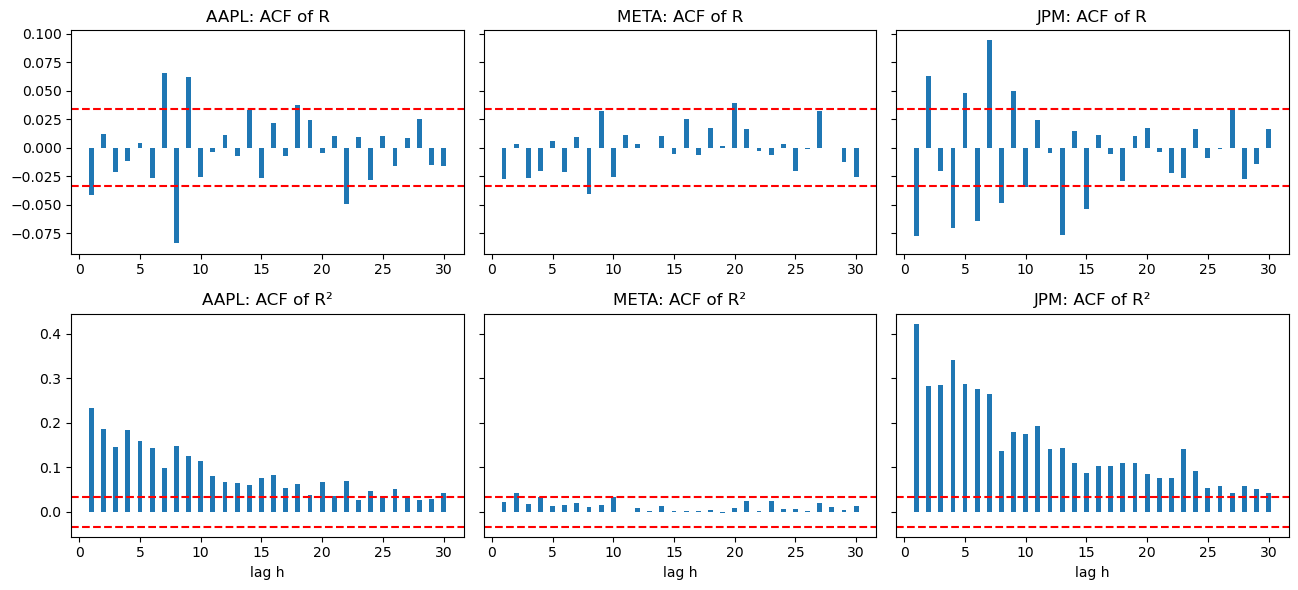

Ljung-Box test results
          Q (R)  p-value (R)     Q (R²)  p-value (R²)
stock                                                
AAPL    64.4300       0.0000   849.2934         0.000
META    19.5762       0.0335    19.0975         0.039
JPM    124.2931       0.0000  2607.4927         0.000


In [6]:
# Question 1 (b) 
from statsmodels.tsa.stattools import acf
from statsmodels.stats.diagnostic import acorr_ljungbox

n = len(returns)
band = 1.96 / np.sqrt(n)          # 95% band if the data were i.i.d.
lags = range(1, 31)               # lags 1, 2, ..., 30

fig, axes = plt.subplots(2, 3, figsize=(13, 6), sharey="row")

for i, tic in enumerate(TICKERS):
    r = returns[tic]
    r2 = r ** 2

    # ACF of the returns
    acf_r = acf(r, nlags=30)[1:]          # [1:] removes lag 0 (always 1)
    axes[0, i].bar(lags, acf_r, width=0.4)
    axes[0, i].axhline(band, color="red", ls="--")
    axes[0, i].axhline(-band, color="red", ls="--")
    axes[0, i].set_title(f"{tic}: ACF of R")

    # ACF of the squared returns
    acf_r2 = acf(r2, nlags=30)[1:]
    axes[1, i].bar(lags, acf_r2, width=0.4)
    axes[1, i].axhline(band, color="red", ls="--")
    axes[1, i].axhline(-band, color="red", ls="--")
    axes[1, i].set_title(f"{tic}: ACF of R²")
    axes[1, i].set_xlabel("lag h")

plt.tight_layout()
plt.savefig(OUT_DIR / "fig_q1b_acf.png", dpi=200)
plt.show()

# Ljung-Box test with H = 10
print("Ljung-Box test results")
results = []
for tic in TICKERS:
    r = returns[tic]
    lb_r = acorr_ljungbox(r, lags=[LB_LAGS])
    lb_r2 = acorr_ljungbox(r ** 2, lags=[LB_LAGS])
    results.append({"stock": tic,
                    "Q (R)": lb_r["lb_stat"].iloc[0],
                    "p-value (R)": lb_r["lb_pvalue"].iloc[0],
                    "Q (R²)": lb_r2["lb_stat"].iloc[0],
                    "p-value (R²)": lb_r2["lb_pvalue"].iloc[0]})

lb_table = pd.DataFrame(results).set_index("stock")
print(lb_table.round(4))

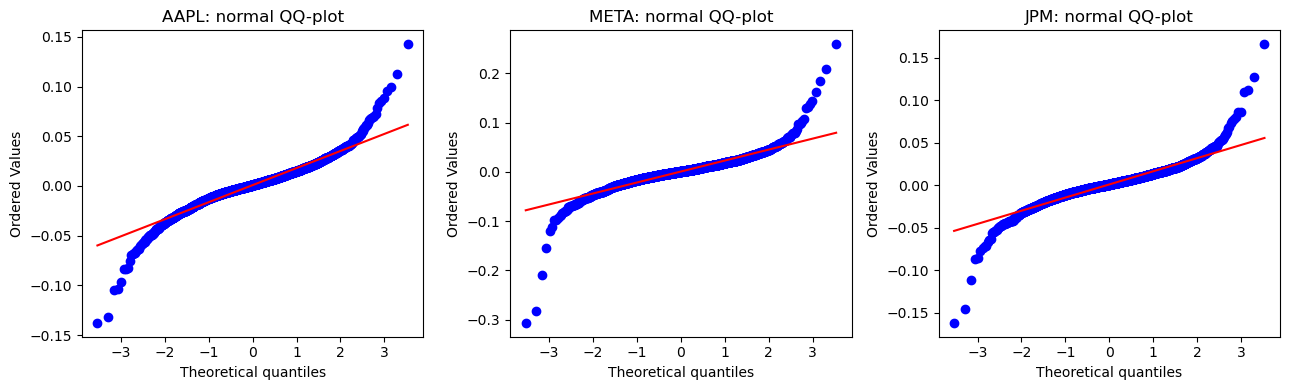

       skewness  kurtosis          JB  p-value
stock                                         
AAPL    -0.2247    9.8139   6590.6140      0.0
META    -0.4974   27.3901  84216.0510      0.0
JPM     -0.0843   15.9363  23655.8191      0.0


In [7]:
# Question 1 (c) 

fig, axes = plt.subplots(1, 3, figsize=(13, 4))

for i, tic in enumerate(TICKERS):
    r = returns[tic]
    stats.probplot(r, dist="norm", plot=axes[i])   # QQ-plot against the normal
    axes[i].set_title(f"{tic}: normal QQ-plot")

plt.tight_layout()
plt.savefig(OUT_DIR / "fig_q1c_qq.png", dpi=200)
plt.show()

# Jarque-Bera test + skewness and kurtosis
results = []
for tic in TICKERS:
    r = returns[tic]
    jb_stat, jb_pvalue = stats.jarque_bera(r)
    results.append({"stock": tic,
                    "skewness": stats.skew(r),
                    "kurtosis": stats.kurtosis(r, fisher=False),   # normal = 3
                    "JB": jb_stat,
                    "p-value": jb_pvalue})

jb_table = pd.DataFrame(results).set_index("stock")
print(jb_table.round(4))

## Question 2 -- Single-window VaR and ES estimates

For each stock, use the first `WINDOW` losses as the single estimation window for (a)-(d).

In [8]:
# Question 2
window_loss = losses.iloc[:WINDOW]          # one column per stock
W = len(window_loss)                        
print("Window:", window_loss.index[0].date(), "to", window_loss.index[-1].date())


# Historical simulation
def hs_var_es(L, alpha):
    L_sorted = np.sort(L)[::-1]                 # largest loss first
    k = int(np.floor(W * (1 - alpha)))         
    var = L_sorted[k]                           
    es = (L_sorted[:k].sum() + (W * (1 - alpha) - k) * L_sorted[k]) / (W * (1 - alpha))
    return var, es

Window: 2013-01-03 to 2015-01-02


In [9]:
# Gaussian 
def normal_var_es(mu, sigma, alpha):
    z = stats.norm.ppf(alpha)                  
    var = mu + sigma * z
    es = mu + sigma * stats.norm.pdf(z) / (1 - alpha)
    return var, es

In [10]:
# Student-t
def t_var_es(nu, mu, sigma, alpha):
    q = stats.t.ppf(alpha, nu)                  # quantile of the standard t_nu
    var = mu + sigma * q
    es = mu + sigma * stats.t.pdf(q, nu) / (1 - alpha) * (nu + q**2) / (nu - 1)
    return var, es


def fit_t(L):
    """ML fit of (nu, mu, sigma) from several starting values of nu; keep the best."""
    best = None
    for nu_start in [2.5, 4, 6, 10, 30]:
        nu, mu, sigma = stats.t.fit(L, nu_start, loc=np.median(L), scale=np.std(L))
        loglik = stats.t.logpdf(L, nu, mu, sigma).sum()
        if best is None or loglik > best[3]:
            best = (nu, mu, sigma, loglik)
    return best

In [11]:
# Compute VaR and ES for every alpha and with every method
rows = []        # VaR / ES results
params = {}      # fitted parameters

for tic in TICKERS:
    L = window_loss[tic].values

    mu_n = L.mean()
    sigma_n = L.std(ddof=1)
    nu, mu_t, sigma_t, loglik = fit_t(L)
    params[tic] = {"mu_n": mu_n, "sigma_n": sigma_n,
                   "nu": nu, "mu_t": mu_t, "sigma_t": sigma_t}

    for alpha in ALPHAS:
        var, es = hs_var_es(L, alpha)
        rows.append({"stock": tic, "alpha": alpha, "method": "HS", "VaR": var, "ES": es})
        var, es = normal_var_es(mu_n, sigma_n, alpha)
        rows.append({"stock": tic, "alpha": alpha, "method": "Gaussian", "VaR": var, "ES": es})
        var, es = t_var_es(nu, mu_t, sigma_t, alpha)
        rows.append({"stock": tic, "alpha": alpha, "method": "Student-t", "VaR": var, "ES": es})

q2 = pd.DataFrame(rows)

# Fitted parameters
param_table = pd.DataFrame(params).T
param_table["sd_t"] = param_table["sigma_t"] * np.sqrt(param_table["nu"] / (param_table["nu"] - 2))
print("\nFitted parameters:")
print(param_table.round(4))

# VaR and ES tables, in %, the three stocks side by side
print("\nVaR (%):")
print((100 * q2.pivot_table(index=["alpha", "method"], columns="stock", values="VaR")[TICKERS]).round(2))
print("\nES (%):")
print((100 * q2.pivot_table(index=["alpha", "method"], columns="stock", values="ES")[TICKERS]).round(2))



Fitted parameters:
        mu_n  sigma_n      nu    mu_t  sigma_t    sd_t
AAPL -0.0007   0.0160  4.1324 -0.0011   0.0111  0.0155
META -0.0020   0.0251  4.6793 -0.0013   0.0178  0.0235
JPM  -0.0008   0.0116  6.4827 -0.0010   0.0097  0.0117

VaR (%):
stock            AAPL  META   JPM
alpha method                     
0.975 Gaussian   3.07  4.72  2.20
      HS         2.90  4.23  2.38
      Student-t  2.95  4.54  2.24
0.990 Gaussian   3.65  5.64  2.62
      HS         3.89  5.35  2.78
      Student-t  3.99  6.03  2.89

ES (%):
stock            AAPL  META   JPM
alpha method                     
0.975 Gaussian   3.67  5.67  2.64
      HS         4.97  5.60  2.92
      Student-t  4.25  6.35  2.99
0.990 Gaussian   4.20  6.49  3.02
      HS         7.39  6.53  3.54
      Student-t  5.56  8.14  3.69


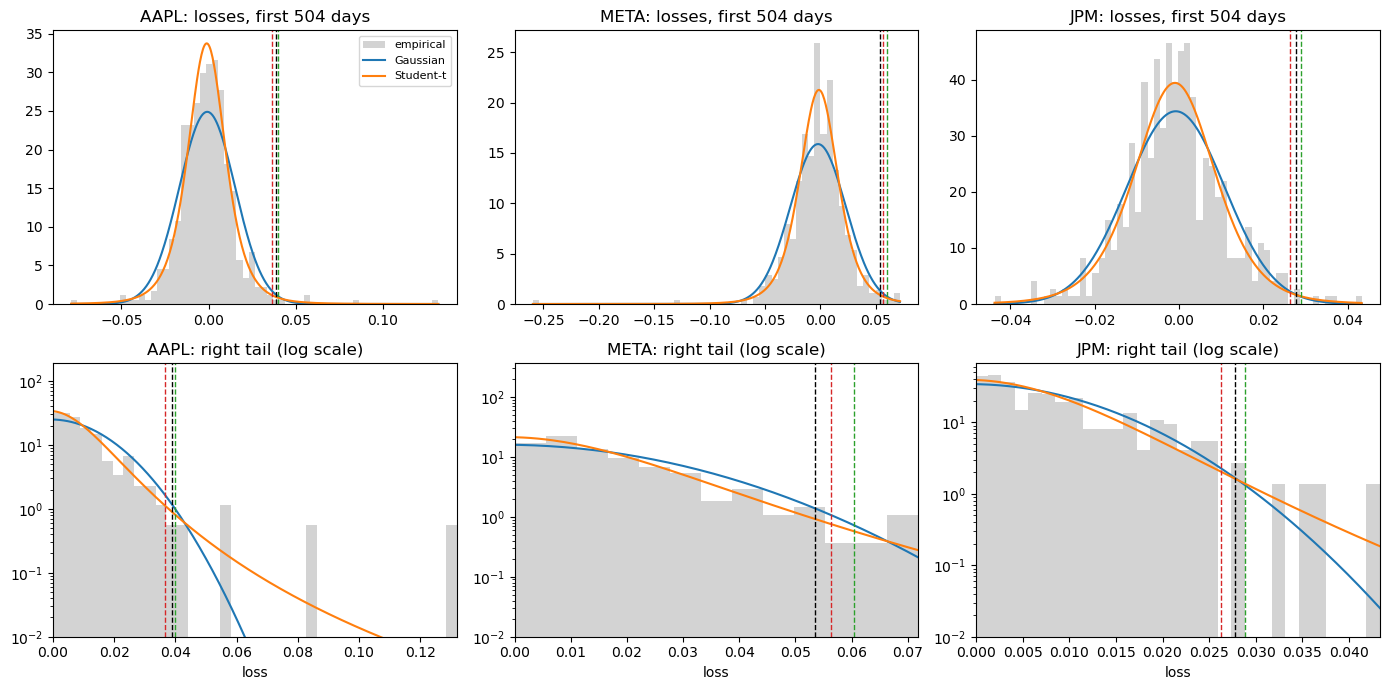

In [12]:
fig, axes = plt.subplots(2, 3, figsize=(14, 7))
for i, tic in enumerate(TICKERS):
    L = window_loss[tic].values
    p = params[tic]
    x = np.linspace(L.min(), L.max(), 500)

    for row in [0, 1]:
        ax = axes[row, i]
        ax.hist(L, bins=60, density=True, color="lightgrey", label="empirical")
        ax.plot(x, stats.norm.pdf(x, p["mu_n"], p["sigma_n"]), label="Gaussian")
        ax.plot(x, stats.t.pdf(x, p["nu"], p["mu_t"], p["sigma_t"]), label="Student-t")

        # VaR at 99% of the three methods
        for method, color in [("HS", "black"), ("Gaussian", "tab:red"), ("Student-t", "tab:green")]:
            v = q2[(q2.stock == tic) & (q2.alpha == 0.99) & (q2.method == method)]["VaR"].iloc[0]
            ax.axvline(v, color=color, ls="--", lw=1)

    axes[0, i].set_title(f"{tic}: losses, first {W} days")
    axes[1, i].set_yscale("log")                
    axes[1, i].set_xlim(0, L.max())             
    axes[1, i].set_title(f"{tic}: right tail (log scale)")
    axes[1, i].set_xlabel("loss")
    axes[1, i].set_ylim(1e-2, None)             

axes[0, 0].legend(fontsize=8)
plt.tight_layout()
plt.savefig(OUT_DIR / "fig_q2_densities.png", dpi=200)
plt.show()

## Question 3 -- Backtesting

Forecast every day of the evaluation period `losses.iloc[EVAL_START:]`, each model estimated on the
`WINDOW` days before the forecast day. Historical simulation, Gaussian and Student-$t$ are recomputed
every day. Write the Kupiec, Christoffersen, Acerbi-Szekely, Fissler-Ziegel, pinball-loss and
Diebold-Mariano functions yourself, from the course slides (Kupiec, Christoffersen) and Appendix A of
the project statement (the others); they are
reused unchanged in Questions 4 and 5.

The combined VaR backtest table collects the VaR backtests of Questions 3-5: append one row per
stock, method and level to `backtest_rows` as you go. The ES backtest table ($\alpha=0.975$) collects
the Acerbi-Szekely and Fissler-Ziegel results of Questions 3 and 4 in `es_rows`.

In [ ]:
# Question 3
eval_loss = losses.iloc[EVAL_START:]        # one column per stock, 2888 forecast days
backtest_rows = []                          # dicts: stock, method, alpha, x, expected, hit, p_uc, p_ind, p_cc, pinball_bp
es_rows = []                                # dicts: stock, method, Z, p_Z, FZ


In [49]:
# Question 3, step 1: rolling one-day-ahead VaR/ES forecasts
# The forecast for day i uses the WINDOW losses before it, i.e. data up to day i-1 only.
fc = {}   # fc[tic]: one row per forecast day, fitted parameters + VaR/ES of each method and level

for tic in TICKERS:
    loss = losses[tic]
    nu, mu_t, sigma_t, _ = fit_t(loss.iloc[:WINDOW].values)   # multi-start fit on the first window only
    rows = []
    for i in range(EVAL_START, len(loss)):
        window = loss.iloc[i - WINDOW:i].values
        mu_n, sigma_n = window.mean(), window.std(ddof=1)
        # start the t fit from yesterday's estimates: one fit per day, avoids local optima
        nu, mu_t, sigma_t = stats.t.fit(window, nu, loc=mu_t, scale=sigma_t)

        row = {"mu_n": mu_n, "sigma_n": sigma_n, "nu": nu, "mu_t": mu_t, "sigma_t": sigma_t}
        for alpha in ALPHAS:
            row[f"HS_VaR_{alpha}"], row[f"HS_ES_{alpha}"] = hs_var_es(window, alpha)
            row[f"Gaussian_VaR_{alpha}"], row[f"Gaussian_ES_{alpha}"] = normal_var_es(mu_n, sigma_n, alpha)
            row[f"Student-t_VaR_{alpha}"], row[f"Student-t_ES_{alpha}"] = t_var_es(nu, mu_t, sigma_t, alpha)
        rows.append(row)
    fc[tic] = pd.DataFrame(rows, index=loss.index[EVAL_START:])

# Check: the first forecast uses the Question 2 window, so it should reproduce the Question 2 table
print(fc["AAPL"].iloc[0].filter(like="VaR"))
print(q2[q2.stock == "AAPL"][["alpha", "method", "VaR"]])

# Fitted Student-t degrees of freedom over the evaluation period
print("\nRolling Student-t nu:")
print(pd.DataFrame({tic: fc[tic]["nu"].describe() for tic in TICKERS}).round(2))


HS_VaR_0.975           0.029007
Gaussian_VaR_0.975     0.030675
Student-t_VaR_0.975    0.029466
HS_VaR_0.99            0.038878
Gaussian_VaR_0.99      0.036549
Student-t_VaR_0.99     0.039929
Name: 2015-01-05 00:00:00, dtype: float64
   alpha     method       VaR
0  0.975         HS  0.029007
1  0.975   Gaussian  0.030675
2  0.975  Student-t  0.029466
3  0.990         HS  0.038878
4  0.990   Gaussian  0.036549
5  0.990  Student-t  0.039929

Rolling Student-t nu:
          AAPL     META      JPM
count  2888.00  2888.00  2888.00
mean      4.01     3.48     3.96
std       1.58     0.55     1.59
min       2.33     2.55     1.86
25%       2.93     3.06     2.86
50%       3.25     3.34     3.55
75%       4.54     3.84     4.60
max      11.69     5.04     9.87


In [50]:
# Question 3, step 2: VaR backtests (Kupiec, Christoffersen, pinball loss)
from scipy.special import xlogy   # xlogy(a, b) = a * log(b), with 0 * log(0) = 0 (e.g. no consecutive exceptions)


def LR_uc(x, n, p0):
    """Kupiec unconditional coverage LR statistic, chi2(1) under H0."""
    p = x / n
    return 2 * (xlogy(x, p / p0) + xlogy(n - x, (1 - p) / (1 - p0)))


def transitions(I):
    I = np.array(I)
    prev, curr = I[:-1], I[1:]
    n00 = np.sum((prev == 0) & (curr == 0))
    n01 = np.sum((prev == 0) & (curr == 1))
    n10 = np.sum((prev == 1) & (curr == 0))
    n11 = np.sum((prev == 1) & (curr == 1))
    return n00, n01, n10, n11


def LR_ind(I):
    """Christoffersen independence LR statistic, chi2(1) under H0."""
    n00, n01, n10, n11 = transitions(I)
    p01 = n01 / (n00 + n01)
    p11 = n11 / (n10 + n11)
    p = (n01 + n11) / (n00 + n01 + n10 + n11)
    l0 = xlogy(n01 + n11, p) + xlogy(n00 + n10, 1 - p)
    l1 = xlogy(n01, p01) + xlogy(n00, 1 - p01) + xlogy(n11, p11) + xlogy(n10, 1 - p11)
    return -2 * (l0 - l1)


def pinball(v, L, alpha):
    """Daily pinball loss of VaR forecasts v for realized losses L (Appendix A.1)."""
    return ((L <= v) - alpha) * (v - L)


def var_backtest(L, v, alpha):
    """All VaR backtest columns for one series of forecasts v against realized losses L."""
    I = (L > v).astype(int)
    n, x = len(I), I.sum()
    lr_uc, lr_ind = LR_uc(x, n, 1 - alpha), LR_ind(I)
    return {"x": x, "expected": n * (1 - alpha), "hit": x / n,
            "p_uc": stats.chi2.sf(lr_uc, 1),
            "p_ind": stats.chi2.sf(lr_ind, 1),
            "p_cc": stats.chi2.sf(lr_uc + lr_ind, 2),
            "pinball_bp": 1e4 * pinball(v, L, alpha).mean()}


for tic in TICKERS:
    for method in ["HS", "Gaussian", "Student-t"]:
        for alpha in ALPHAS:
            v = fc[tic][f"{method}_VaR_{alpha}"]
            backtest_rows.append({"stock": tic, "method": method, "alpha": alpha,
                                  **var_backtest(eval_loss[tic], v, alpha)})

var_table = pd.DataFrame(backtest_rows).set_index(["alpha", "stock", "method"]).sort_index()
for alpha in ALPHAS:
    print(f"\nVaR backtests, alpha = {alpha}")
    print(var_table.loc[alpha].round(3))


VaR backtests, alpha = 0.975
                   x  expected    hit   p_uc  p_ind   p_cc  pinball_bp
stock method                                                          
AAPL  Gaussian   105      72.2  0.036  0.000  0.000  0.000      13.748
      HS          86      72.2  0.030  0.110  0.004  0.005      13.601
      Student-t  103      72.2  0.036  0.001  0.000  0.000      13.716
JPM   Gaussian    95      72.2  0.033  0.009  0.000  0.000      13.207
      HS          83      72.2  0.029  0.208  0.000  0.000      13.023
      Student-t   92      72.2  0.032  0.023  0.000  0.000      13.303
META  Gaussian    78      72.2  0.027  0.495  0.000  0.001      18.321
      HS          75      72.2  0.026  0.740  0.016  0.051      18.262
      Student-t   89      72.2  0.031  0.053  0.000  0.000      18.285

VaR backtests, alpha = 0.99
                  x  expected    hit   p_uc  p_ind   p_cc  pinball_bp
stock method                                                         
AAPL  Gaussian   62 

### Question 3(b) — Coverage and independence failures

All tests are at the 5% level. Over the 2,888 forecast days, every method at both levels produces more exceptions than expected (all hit rates are above $1-\alpha$), so all three unconditional methods underestimate risk on average.

**Coverage (Kupiec).**
- *Gaussian* fails at $\alpha=0.99$ for all three stocks, with 52–64 exceptions against 28.9 expected (hit rates of 1.8–2.2% against 1%). At $\alpha=0.975$ it fails for AAPL and JPM and passes only for META. The normal tail is too thin, and the problem gets worse deeper in the tail.
- *Student-t* fails at $\alpha=0.975$ for AAPL and JPM (META is borderline, $p=0.053$). At $\alpha=0.99$ it fails for AAPL and JPM and passes for META. The rolling fits give a small $\hat\nu$ (median between 3.25 and 3.55 across the three stocks, interquartile range 2.86–4.60). Such a $t$ has a heavy tail but a narrow centre, so its 97.5% quantile sits too low. At 99% it does about as well as historical simulation.
- *Historical simulation* passes at $\alpha=0.975$ for all three stocks. At $\alpha=0.99$ it fails narrowly for all three ($p$ between 0.022 and 0.049), with 40–42 exceptions against 28.9 expected.

**Independence (Christoffersen).** At $\alpha=0.975$ every method fails independence for every stock: exceptions come in clusters. This is the volatility clustering from Question 1. A 504-day unconditional window adapts too slowly, so when volatility rises the VaR stays too low for weeks and exceptions pile up on consecutive days. At $\alpha=0.99$ the Gaussian model still fails for all three stocks and HS and Student-$t$ fail for JPM. HS and Student-$t$ pass for AAPL and META. With only 38–47 exceptions for these two methods, pairs of consecutive exceptions are rare, so the test has little power at this level. Passing it there is weak evidence of independence.

**Where Kupiec and conditional coverage disagree.** At $\alpha=0.975$ four cases pass Kupiec but fail conditional coverage: HS for AAPL and JPM, Gaussian for META, and Student-$t$ for META. In each, the number of exceptions is close to the expected number and the independence $p$-value is below 0.005, so the failure comes from clustering, not from the exception count. META–HS at $\alpha=0.975$ shows the opposite effect: independence fails ($p=0.016$), but conditional coverage passes narrowly ($p=0.051$), because the joint test spreads the evidence over two degrees of freedom and loses power. No case fails Kupiec while passing conditional coverage.

**Summary.** The only method that passes all three tests at a given level is Student-$t$ for META at $\alpha=0.99$. At $\alpha=0.975$, independence fails for every method, which points to the lack of conditioning on current volatility, the motivation for the GARCH models of Question 4.


In [51]:
# Question 3(c): Acerbi-Szekely Z test of the ES forecasts at alpha = 0.975 (Appendix A.2)
ALPHA_ES = 0.975


def draw_losses(tic, method, i, M):
    """M losses from the forecast distribution of forecast day i (0 = first day of eval_loss)."""
    p = fc[tic].iloc[i]
    if method == "HS":                                  # resample that day's estimation window
        j = EVAL_START + i
        return rng.choice(losses[tic].values[j - WINDOW:j], M)
    if method == "Gaussian":
        return rng.normal(p["mu_n"], p["sigma_n"], M)
    return p["mu_t"] + p["sigma_t"] * rng.standard_t(p["nu"], M)   # Student-t


def as_test(tic, method, alpha=ALPHA_ES, M=M_SIM):
    """Observed Z, its one-sided simulated p-value (each day's forecasts held fixed),
    the split 1 + Z = freq x sev, and the mean / sd of the simulated null distribution."""
    L = eval_loss[tic].values
    v = fc[tic][f"{method}_VaR_{alpha}"].values
    e = fc[tic][f"{method}_ES_{alpha}"].values
    n = len(L)
    I = L > v

    Z = np.sum(L * I / e) / (n * (1 - alpha)) - 1

    # Simulate day by day and accumulate each sample's sum, instead of storing an n x M matrix
    acc = np.zeros(M)
    for i in range(n):
        L_sim = draw_losses(tic, method, i, M)
        acc += L_sim * (L_sim > v[i]) / e[i]
    Z_sim = acc / (n * (1 - alpha)) - 1

    return {"Z": Z, "p_Z": np.mean(Z_sim >= Z),
            "freq": I.sum() / (n * (1 - alpha)),        # exceptions relative to the expected number
            "sev": np.mean(L[I] / e[I]),                # average loss / forecast ES on exception days
            "Z_null_mean": Z_sim.mean(), "Z_null_sd": Z_sim.std()}


for tic in TICKERS:
    for method in ["HS", "Gaussian", "Student-t"]:
        es_rows.append({"stock": tic, "method": method, **as_test(tic, method)})

es_table = pd.DataFrame(es_rows).set_index(["stock", "method"])
print(f"Acerbi-Szekely Z test, alpha = {ALPHA_ES}, M = {M_SIM}")
print(es_table.round(4))


Acerbi-Szekely Z test, alpha = 0.975, M = 10000
                      Z     p_Z    freq     sev  Z_null_mean  Z_null_sd
stock method                                                           
AAPL  HS         0.2476  0.0121  1.1911  1.0474      -0.0335     0.1195
      Gaussian   0.7803  0.0000  1.4543  1.2242       0.0006     0.1174
      Student-t  0.3720  0.0054  1.4266  0.9617      -0.0005     0.1356
META  HS         0.1252  0.1166  1.0388  1.0831      -0.0311     0.1296
      Gaussian   0.4947  0.0003  1.0803  1.3835       0.0024     0.1171
      Student-t  0.3294  0.0116  1.2327  1.0785       0.0006     0.1358
JPM   HS         0.2505  0.0111  1.1496  1.0878      -0.0342     0.1190
      Gaussian   0.7317  0.0000  1.3158  1.3161       0.0002     0.1167
      Student-t  0.3514  0.0101  1.2742  1.0605      -0.0023     0.1406


### Question 3(c) — Acerbi–Székely Z test ($\alpha = 0.975$, $M = 10{,}000$)

| | HS | Gaussian | Student-$t$ |
|---|---|---|---|
| AAPL | 0.2476 (0.0121) | 0.7803 (0.0000) | 0.3720 (0.0054) |
| META | 0.1252 (0.1166) | 0.4947 (0.0003) | 0.3294 (0.0116) |
| JPM  | 0.2505 (0.0111) | 0.7317 (0.0000) | 0.3514 (0.0101) |

*$Z$ with its simulated one-sided $p$-value in brackets. A $p$-value of 0.0000 means none of the 10,000 simulated $Z$ reached the observed value.*

**Results.** Every $Z$ is positive: realized tail losses are larger than the forecast ES predicts. At the 5% level the test rejects every method for every stock except historical simulation on META. The Gaussian model is far worse than the other two, with $Z$ between 0.49 and 0.78.

Writing $x$ for the number of exceptions, $Z$ splits exactly into a frequency factor and a severity factor:
$$
1 + Z \;=\; \underbrace{\frac{x}{n(1-\alpha)}}_{\text{frequency}} \;\times\; \underbrace{\frac{1}{x}\sum_{t:\,I_t=1} \frac{L_t}{\widehat{\mathrm{ES}}_{t,\alpha}}}_{\text{severity}}.
$$

| | HS | Gaussian | Student-$t$ |
|---|---|---|---|
| AAPL | 1.19 × 1.05 | 1.45 × 1.22 | 1.43 × 0.96 |
| META | 1.04 × 1.08 | 1.08 × 1.38 | 1.23 × 1.08 |
| JPM  | 1.15 × 1.09 | 1.32 × 1.32 | 1.27 × 1.06 |

The split shows that the methods fail for different reasons. The Gaussian model fails on both counts: it has too many exceptions, and on exception days the loss exceeds its ES by 22–38% on average, because the normal tail is too thin. The Student-$t$ model's ES is about the right size when an exception occurs (severity 0.96–1.08), so its rejection comes mostly from having too many exceptions at 97.5%. This matches the low 97.5% VaR found in 3(b). Historical simulation is closest on both factors, and on META it has close to the expected number of exceptions (75 against 72.2). It is the only case the test does not reject.

**Why the simulated distribution of $Z$ depends on the method.** Under the null that the forecasts are correct, $Z$ has mean zero (for continuous forecast distributions), but the rest of its distribution depends on what the model assumes about losses beyond the VaR. Each term $L_t I_t / \widehat{\mathrm{ES}}_t$ is a loss beyond VaR scaled by the forecast ES, and how spread out that ratio is depends on the shape of the tail. A heavy-tailed forecast produces some very large exceedances relative to its ES, a thin-tailed one does not. The null distribution of $Z$ therefore depends on the model being tested, not only on $\alpha$ and $n$. This differs from the Kupiec test, where the exception count is Binomial $(n, 1-\alpha)$ under any correctly specified model. This is why the null is simulated from each method's own daily forecast distributions. The simulations show it: the standard deviation of the simulated $Z$ is 0.117 for the Gaussian, 0.119–0.130 for HS, and 0.136–0.141 for the Student-$t$, so the same observed $Z$ is less significant under the heavier-tailed model. For historical simulation the forecast distribution is discrete (resampling the 504-day window), so $\mathbb{E}[Z]=0$ holds only approximately: the simulated null mean is between $-0.034$ and $-0.031$ for HS, against at most $0.003$ in absolute value for the two continuous models.


In [52]:
# Question 3(d): Fissler-Ziegel joint score and Diebold-Mariano test at alpha = 0.975 (Appendix A.3)
import statsmodels.api as sm


def fz_score(v, e, L, alpha):
    """Daily Fissler-Ziegel (Patton et al.) score of the VaR/ES pair (v, e) for losses L; lower is better."""
    I = (L > v)
    return I / ((1 - alpha) * e) * (L - v) + v / e + np.log(e) - 1


def dm_test(d):
    """Diebold-Mariano test of E[d_t] = 0: t-test on the mean with a Newey-West (HAC) standard error."""
    res = sm.OLS(np.asarray(d), np.ones(len(d))).fit(cov_type="HAC", cov_kwds={"maxlags": NW_LAGS})
    return res.params[0], res.tvalues[0], res.pvalues[0]


# Daily scores, one column per method (Question 4(d) adds the GARCH columns and reuses them)
fz = {}
for tic in TICKERS:
    fz[tic] = pd.DataFrame({
        method: fz_score(fc[tic][f"{method}_VaR_{ALPHA_ES}"], fc[tic][f"{method}_ES_{ALPHA_ES}"],
                         eval_loss[tic], ALPHA_ES)
        for method in ["HS", "Gaussian", "Student-t"]})

# Average score -> FZ column of the ES table
for row in es_rows:
    row["FZ"] = fz[row["stock"]][row["method"]].mean()
es_table = pd.DataFrame(es_rows).set_index(["stock", "method"])
print(f"ES backtests, alpha = {ALPHA_ES}")
print(es_table[["Z", "p_Z", "FZ"]].round(4))

# Rank the methods by average score, then DM test best vs second best (d_t = S_best - S_second)
dm_rows = []
for tic in TICKERS:
    ranking = fz[tic].mean().sort_values()
    best, second = ranking.index[0], ranking.index[1]
    mean_d, t_dm, p_dm = dm_test(fz[tic][best] - fz[tic][second])
    dm_rows.append({"stock": tic, "ranking": " < ".join(ranking.index),
                    "best": best, "second": second, "mean_d": mean_d, "t_DM": t_dm, "p_DM": p_dm})
dm_table = pd.DataFrame(dm_rows).set_index("stock")
print("\nFZ ranking (lowest score first) and DM test, best vs second best")
print(dm_table.round(4))


ES backtests, alpha = 0.975
                      Z     p_Z      FZ
stock method                           
AAPL  HS         0.2476  0.0121 -2.9104
      Gaussian   0.7803  0.0000 -2.8340
      Student-t  0.3720  0.0054 -2.8997
META  HS         0.1252  0.1166 -2.6174
      Gaussian   0.4947  0.0003 -2.5366
      Student-t  0.3294  0.0116 -2.5956
JPM   HS         0.2505  0.0111 -2.9591
      Gaussian   0.7317  0.0000 -2.8624
      Student-t  0.3514  0.0101 -2.9145

FZ ranking (lowest score first) and DM test, best vs second best
                         ranking best     second  mean_d    t_DM    p_DM
stock                                                                   
AAPL   HS < Student-t < Gaussian   HS  Student-t -0.0107 -1.0140  0.3106
META   HS < Student-t < Gaussian   HS  Student-t -0.0218 -1.3558  0.1752
JPM    HS < Student-t < Gaussian   HS  Student-t -0.0446 -2.5899  0.0096


### Question 3(d) — Fissler–Ziegel ranking and Diebold–Mariano test ($\alpha = 0.975$)

| Average FZ score (lower is better) | HS | Gaussian | Student-$t$ |
|---|---|---|---|
| AAPL | **−2.9104** | −2.8340 | −2.8997 |
| META | **−2.6174** | −2.5366 | −2.5956 |
| JPM  | **−2.9591** | −2.8624 | −2.9145 |

**Ranking.** The ranking is the same for all three stocks: historical simulation first, Student-$t$ second, Gaussian last. It matches the Acerbi–Székely results of 3(c), where HS has the smallest $Z$ and the Gaussian the largest for every stock.

**Diebold–Mariano test, best against second best.** With $d_t = S_t^{\text{HS}} - S_t^{t}$ and a Newey–West standard error with 10 lags:

| | mean $d_t$ | $t_{DM}$ | $p$-value |
|---|---|---|---|
| AAPL | −0.0107 | −1.0140 | 0.3106 |
| META | −0.0218 | −1.3558 | 0.1752 |
| JPM  | −0.0446 | −2.5899 | 0.0096 |

For JPM, HS has a significantly lower average score than the Student-$t$ at the 5% level (and at 1%). For AAPL and META the difference is not significant: the data cannot separate the two methods, even though HS ranks first.

**What the test tells us.** The null hypothesis is that both methods have the same expected score, $\mathbb{E}[d_t] = 0$. The FZ score is strictly consistent for the pair (VaR, ES), so a lower expected score means more accurate VaR/ES forecasts. A rejection, as for JPM, therefore says that over this evaluation period HS produced more accurate forecasts than the Student-$t$. The HAC standard error is needed because $d_t$ is autocorrelated, especially in volatile periods, which an ordinary $t$-test would ignore.

**What it does not tell us.**
- *It is a relative comparison, not a test of correct specification.* Both methods can be wrong, and the better one is still rejected by the absolute backtests: for JPM, HS fails the $Z$ test ($p=0.0111$) and conditional coverage at 97.5% ($p<0.001$). Being "significantly better" only means less wrong.
- *A non-rejection does not mean the methods are equivalent.* For AAPL and META the test may simply lack the power to detect a difference over 2,888 days, given how noisy the daily score differences are.
- *The result holds for this sample and these two methods.* It says nothing about periods outside the evaluation sample, and since the pair was picked after looking at the ranking, the $p$-value overstates the evidence somewhat.


## Question 4 -- AR-GARCH conditional VaR and ES (25 points)

**Scope and notation.** Work separately on AAPL, META and JPM. Follow Question 4 (pp. 3–4), the rolling strategy and combined-table rules (p. 2), and Appendices A.1–A.4 of `docs/QRM_2026_Project.pdf`. Question 4 selects the autoregressive mean specification, estimates Gaussian and standardized Student-t GARCH models, produces rolling conditional VaR and ES forecasts, and evaluates their performance through comparative backtesting.

For returns $R_t$ and losses $L_t=-R_t$, the model is
$$
R_t=\mu_t+\varepsilon_t,\qquad
\mu_t=\mu+\sum_{i=1}^{p}\phi_i(R_{t-i}-\mu),\qquad
\varepsilon_t=\sigma_t Z_t,
$$
$$
\sigma_t^2=\alpha_0+\alpha_1\varepsilon_{t-1}^2+\beta_1\sigma_{t-1}^2,
\qquad \alpha_0>0,\quad \alpha_1,\beta_1\geq0,\quad \alpha_1+\beta_1<1.
$$
The innovations $Z_t$ are i.i.d. with mean zero and variance one, either standard Gaussian or standardized Student-$t$ ($\nu>2$). The variance recursion uses **mean residuals $\varepsilon_t$**, not raw returns. Use an AR mean (no moving-average terms); document how the variance recursion is initialized, including the initialization/backcast used by the fitting routine.

Full-sample fits in (a)–(b) select and diagnose the model. Part (c) estimates forecasting parameters within each rolling window. Estimate on returns in percent ($y_t=100R_t$); report units explicitly and convert risk forecasts back to the original log-loss scale.

In [13]:
import sys
from arch import arch_model


def q4_require(condition, message, error=ValueError):
    """Stop on invalid inputs/results; unlike assert, also active with Python -O."""
    if not condition:
        raise error(message)


### Question 4(a) — Mean Model: AR(p)

#### (i) Model selection

**Objective.** Select one AR order per stock before fitting conditional variance dynamics.

**Required calculations.** Fit AR($p$), $p\in\{0,1,2,3\}$, with constant variance by Gaussian quasi-maximum likelihood on the full sample. Condition on the first three returns in every candidate (`hold_back=3`, e.g. `ARX(y, lags=p, hold_back=3)`), so likelihoods use identical observations. With $n$ retained observations and $k=p+2$ estimated parameters (mean, $p$ AR coefficients and variance), compute
$$
\mathrm{AIC}=-2\log\widehat{\mathcal L}+2k,\qquad
\mathrm{BIC}=-2\log\widehat{\mathcal L}+k\log n.
$$
Choose the order minimizing BIC and keep it fixed in (b)–(d).

**Expected outputs.** A shared table showing AIC and BIC for all four orders for each stock, the BIC-selected order, and whether AIC selects the same order.

**Interpretation.** Smaller criteria are preferred. Under its usual assumptions, BIC consistently selects the true order if it is among the candidates; AIC tends to select orders that are too large (Appendix A.4). Record any disagreement.

In [14]:
# Question 4(a)(i): full-sample AR order selection in percentage units.
q4_selection_rows = []
q4_summary_rows = []
q4_selected_p = {}

for q4_stock in TICKERS:
    q4_y = 100 * returns[q4_stock]
    q4_stock_rows = []
    for q4_p in range(4):
        # p=0 has a constant mean; every candidate conditions on three returns.
        q4_model = arch_model(
            q4_y,
            mean="Constant" if q4_p == 0 else "AR",
            lags=q4_p,
            vol="Constant",
            dist="normal",
            hold_back=3,
            rescale=False,
        )
        q4_fit = q4_model.fit(disp="off")
        q4_require(q4_fit.nobs == len(q4_y) - 3, 'AR candidates must use identical observations.', ValueError)
        q4_stock_rows.append({
            "Stock": q4_stock, "AR order p": q4_p,
            "AIC": q4_fit.aic, "BIC": q4_fit.bic,
        })

    # In an exact tie, choose the smaller order (candidates are ordered by p).
    q4_aic_p = min(q4_stock_rows, key=lambda row: row["AIC"])["AR order p"]
    q4_bic_p = min(q4_stock_rows, key=lambda row: row["BIC"])["AR order p"]
    q4_selected_p[q4_stock] = q4_bic_p
    for q4_row in q4_stock_rows:
        q4_row["Selected by AIC"] = q4_row["AR order p"] == q4_aic_p
        q4_row["Selected by BIC"] = q4_row["AR order p"] == q4_bic_p
    q4_selection_rows.extend(q4_stock_rows)
    q4_summary_rows.append({
        "Stock": q4_stock, "AIC-selected p": q4_aic_p,
        "BIC-selected p": q4_bic_p, "AIC and BIC agree": q4_aic_p == q4_bic_p,
    })

q4_selection_table = pd.DataFrame(q4_selection_rows)
q4_selection_summary = pd.DataFrame(q4_summary_rows)
display(q4_selection_table.style.format({"AIC": "{:.3f}", "BIC": "{:.3f}"}))
display(q4_selection_summary)


,Stock,AR order p,AIC,BIC,Selected by AIC,Selected by BIC
0,AAPL,0,13524.670,13536.927,False,True
1,AAPL,1,13520.620,13539.005,True,False
2,AAPL,2,13522.266,13546.779,False,False
3,AAPL,3,13522.881,13553.522,False,False
4,META,0,15579.299,15591.556,False,True
5,META,1,15578.686,15597.071,True,False
6,META,2,15580.669,15605.182,False,False
7,META,3,15580.332,15610.974,False,False
8,JPM,0,12940.813,12953.070,False,False
9,JPM,1,12922.654,12941.039,False,False


,Stock,AIC-selected p,BIC-selected p,AIC and BIC agree
0,AAPL,1,0,False
1,META,1,0,False
2,JPM,2,2,True


4(a)(i) – Results and Interpretation

BIC selects AR(0) for AAPL and META and AR(2) for JPM, with minimum BIC values of 13536.927, 15591.556 and 12937.969, respectively. AIC selects AR(1), AR(1) and AR(2), so the criteria agree only for JPM. All candidates use the same 3,389 observations; BIC's stronger complexity penalty favors the simpler AAPL and META mean specifications.


#### (ii) Parameter estimation

**Objective.** Describe the fitted mean dynamics of the selected constant-variance AR model.

**Required calculations.** Report $\hat\mu$, $\hat\phi_1,\ldots,\hat\phi_p$ and their standard errors. The `arch` parameter `Const` is the intercept $c$, related to the unconditional mean by
$$
c=\mu\left(1-\sum_{i=1}^{p}\phi_i\right),\qquad
\hat\mu=\frac{\hat c}{1-\sum_{i=1}^{p}\hat\phi_i}.
$$
For $p=0$, $\mu=c$. Obtain the standard error of the transformed mean from the joint parameter covariance (e.g. the delta method, including intercept–AR covariance terms); the intercept standard error alone is not the standard error of $\hat\mu$ when $p>0$.

**Expected outputs.** A per-stock parameter summary with estimates, standard errors and clearly stated units; identify the intercept separately if shown.

**Interpretation.** Distinguish the unconditional mean from the regression intercept and the time-varying conditional mean $\mu_t$. Discuss the magnitude and uncertainty of the fitted mean and AR effects.

In [15]:
# Question 4(a)(ii): selected AR mean parameters and robust QML standard errors.
q4_ar_fits = {}
q4_aii_rows = []

for q4_aii_stock in TICKERS:
    q4_aii_p = q4_selected_p[q4_aii_stock]
    q4_aii_y = 100 * returns[q4_aii_stock]
    q4_aii_model = arch_model(
        q4_aii_y,
        mean="Constant" if q4_aii_p == 0 else "AR",
        lags=q4_aii_p,
        vol="Constant",
        dist="normal",
        hold_back=3,
        rescale=False,
    )
    q4_aii_fit = q4_aii_model.fit(disp="off", cov_type="robust")
    q4_require(q4_aii_fit.convergence_flag == 0, 'AR fit did not converge.', RuntimeError)
    q4_require(q4_aii_fit.nobs == len(q4_aii_y) - 3, 'Invalid selected-AR estimation or delta-method covariance.', ValueError)
    q4_ar_fits[q4_aii_stock] = q4_aii_fit

    q4_aii_names = q4_aii_model.parameter_names()
    # arch reports "mu" for AR(0), otherwise the intercept "Const".
    q4_aii_intercept = "mu" if q4_aii_p == 0 else "Const"
    q4_aii_theta = q4_aii_fit.params.loc[q4_aii_names]
    q4_aii_cov = q4_aii_fit.param_cov.loc[q4_aii_names, q4_aii_names]
    q4_require(np.isfinite(q4_aii_cov.to_numpy()).all(), 'Invalid selected-AR estimation or delta-method covariance.', ValueError)
    q4_aii_c = q4_aii_theta.loc[q4_aii_intercept]
    q4_aii_D = 1 - q4_aii_theta.iloc[1:].sum()
    q4_require(not np.isclose(q4_aii_D, 0), 'Unconditional mean denominator is near zero.', ValueError)
    q4_aii_mu = q4_aii_c / q4_aii_D

    if q4_aii_p == 0:
        q4_aii_mu_se = q4_aii_fit.std_err.loc[q4_aii_intercept]
    else:
        # Named axes align the delta-method gradient and robust covariance.
        q4_aii_gradient = pd.Series(q4_aii_c / q4_aii_D**2, index=q4_aii_names)
        q4_aii_gradient.loc[q4_aii_intercept] = 1 / q4_aii_D
        q4_aii_mu_var = float(q4_aii_gradient @ q4_aii_cov @ q4_aii_gradient)
        q4_require(np.isfinite(q4_aii_mu_var) and q4_aii_mu_var >= 0, 'Invalid selected-AR estimation or delta-method covariance.', ValueError)
        q4_aii_mu_se = np.sqrt(q4_aii_mu_var)

    q4_aii_rows.append({
        "Stock": q4_aii_stock, "Selected AR order": q4_aii_p,
        "Parameter": "μ", "Estimate": q4_aii_mu, "Standard error": q4_aii_mu_se,
    })
    for q4_aii_lag, q4_aii_name in enumerate(q4_aii_names[1:], start=1):
        q4_aii_rows.append({
            "Stock": q4_aii_stock, "Selected AR order": q4_aii_p,
            "Parameter": f"φ{q4_aii_lag}",
            "Estimate": q4_aii_theta.loc[q4_aii_name],
            "Standard error": q4_aii_fit.std_err.loc[q4_aii_name],
        })

q4_ar_parameters = pd.DataFrame(q4_aii_rows)
q4_require(np.isfinite(q4_ar_parameters[['Estimate', 'Standard error']].to_numpy()).all(), 'Invalid selected-AR estimation or delta-method covariance.', ValueError)
q4_require((q4_ar_parameters['Standard error'] >= 0).all(), 'Invalid selected-AR estimation or delta-method covariance.', ValueError)
display(
    q4_ar_parameters.style
    .format({"Estimate": "{:.6f}", "Standard error": "{:.6f}"})
    .set_caption("Selected AR mean parameters: μ and its SE in percent; φ and its SE dimensionless. Robust QML covariance.")
    .set_uuid("q4_ar_parameters")
    .hide(axis="index")
)


Stock,Selected AR order,Parameter,Estimate,Standard error
AAPL,0,μ,0.085755,0.030553
META,0,μ,0.087367,0.041371
JPM,2,μ,0.068710,0.027491
JPM,2,φ1,-0.072592,0.043145
JPM,2,φ2,0.057427,0.035992


4(a)(ii) – Results and Interpretation

The estimated unconditional daily means are 0.085755% for AAPL (robust SE 0.030553%), 0.087367% for META (0.041371%) and 0.068710% for JPM (0.027491%). JPM's AR coefficients are −0.072592 (SE 0.043145) and 0.057427 (SE 0.035992); neither is individually significant at 5% under the normal approximation, providing limited evidence of linear return predictability. The unconditional mean is obtained from the fitted intercept as $\hat\mu=\hat c/(1-\sum_i\hat\phi_i)$; its robust delta-method SE incorporates intercept–AR covariance.


#### (iii) Residual diagnostics

**Objective.** Check remaining serial dependence and whether the i.i.d. residual assumption is credible.

**Required calculations.** Remove undefined initial residuals and apply the Ljung–Box statistic with $H=10$:
$$
Q_{\mathrm{LB}}=n(n+2)\sum_{j=1}^{10}\frac{\hat\rho(j)^2}{n-j}.
$$
Use the Appendix A.4 reference distributions $Q_{\mathrm{LB}}(\hat\varepsilon)\approx\chi^2_{10-p}$ (`model_df=p`) and $Q_{\mathrm{LB}}(\hat\varepsilon^2)\approx\chi^2_{10}$ (`model_df=0`). The null assumes i.i.d. residuals; these are approximate reference laws, not valid under volatility clustering. Reject at 5% when the statistic exceeds the corresponding 95% quantile (equivalently, p-value below 0.05).

**Expected outputs.** For each stock and each residual series: statistic, reference degrees of freedom, p-value and 5% decision.

**Interpretation.** Does the squared-residual test support the i.i.d. assumption? If it indicates volatility clustering, explain why rejection on residuals alone cannot establish that the AR order is wrong: its reference distribution relies on an assumption the squared-residual diagnostic calls into question.

In [16]:
# Question 4(a)(iii): diagnostics of existing AR fits; no re-estimation.
from statsmodels.stats.diagnostic import acorr_ljungbox as q4_aiii_ljungbox

q4_aiii_H = 10
q4_aiii_rows = []
for q4_aiii_stock in TICKERS:
    q4_aiii_p = q4_selected_p[q4_aiii_stock]
    q4_aiii_fit = q4_ar_fits[q4_aiii_stock]
    q4_aiii_resid = q4_aiii_fit.resid.dropna()
    q4_require(np.isfinite(q4_aiii_resid.to_numpy()).all(), 'Non-finite AR residuals.', ValueError)
    q4_require(len(q4_aiii_resid) == q4_aiii_fit.nobs, 'AR residuals must be finite and match the fitted observation count.', ValueError)

    for q4_aiii_label, q4_aiii_series, q4_aiii_df in (
        ("Residuals", q4_aiii_resid, q4_aiii_p),
        ("Squared residuals", q4_aiii_resid**2, 0),
    ):
        q4_aiii_test = q4_aiii_ljungbox(
            q4_aiii_series, lags=[10], model_df=q4_aiii_df, return_df=True,
        ).loc[10]
        q4_aiii_rows.append({
            "Stock": q4_aiii_stock,
            "Selected AR order": q4_aiii_p,
            "Series tested": q4_aiii_label,
            "Ljung–Box statistic": q4_aiii_test["lb_stat"],
            "Degrees of freedom": q4_aiii_H - q4_aiii_df,
            "p-value": q4_aiii_test["lb_pvalue"],
            "Reject at 5%": bool(q4_aiii_test["lb_pvalue"] < 0.05),
        })

q4_ar_diagnostics = pd.DataFrame(q4_aiii_rows)
display(
    q4_ar_diagnostics.style
    .format({"Ljung–Box statistic": "{:.3f}", "p-value": "{:.6e}"})
    .set_caption("AR residual Ljung–Box diagnostics (H = 10; approximate χ² reference distributions).")
    .set_uuid("q4_ar_diagnostics")
    .hide(axis="index")
)



Stock,Selected AR order,Series tested,Ljung–Box statistic,Degrees of freedom,p-value,Reject at 5%
AAPL,0,Residuals,64.228,10,5.692899e-10,True
AAPL,0,Squared residuals,861.019,10,1.555165e-178,True
META,0,Residuals,19.808,10,3.112251e-02,True
META,0,Squared residuals,19.334,10,3.622514e-02,True
JPM,2,Residuals,64.451,8,6.194683e-11,True
JPM,2,Squared residuals,2300.416,10,0.000000e+00,True


4(a)(iii) – Results and Interpretation

At lag 10, residual Ljung–Box tests nominally reject for AAPL, META and JPM (p ≈ 5.69×10⁻¹⁰, 0.0311 and 6.19×10⁻¹¹), using 10, 10 and 8 reference degrees of freedom. Squared-residual statistics of 861.019, 19.334 and 2300.416 also reject at 5% with 10 degrees of freedom for every stock; META's p-value is 0.03622514, while JPM's saved p-value underflows to zero. This dependence is consistent with volatility clustering and challenges the i.i.d. assumption underlying the residual test's approximate reference law. Consequently, rejection on residuals alone cannot establish that the BIC-selected AR order is wrong.


### Question 4(b) — Variance Model: GARCH(1,1)

**Objective.** Model conditional heteroskedasticity and compare Gaussian with standardized Student-$t$ innovations in full-sample diagnostic fits.

**Required calculations.** Keep the order chosen in (a) for each stock. Fit AR($p$)–GARCH(1,1) on the full sample with `dist="normal"` and `dist="t"`, using comparable observations (`hold_back=3`). Use `mean="AR"` with the selected lags, or `mean="Constant"` for $p=0$. Report the mean parameters, $\alpha_0,\alpha_1,\beta_1$ and, for Student-$t$, $\nu$; identify `Const` versus $\mu$ as in (a)(ii). Compare AIC/BIC across the two innovation laws and with the constant-variance fit in (a). Document variance initialization and check the stated parameter constraints.

For the **Gaussian** fit, form $\hat z_t=(R_t-\hat\mu_t)/\hat\sigma_t$, omit undefined initial values and repeat the $H=10$ Ljung–Box tests. Appendix A.4 specifies $\chi^2_{10-p}$ for $\hat z_t$ (`model_df=p`) and $\chi^2_{10-2}=\chi^2_8$ for $\hat z_t^2$ (`model_df=2`, an approximation accounting for the two estimated GARCH dynamics parameters). Apply the same 5% rule.

**Expected outputs.** Shared parameter and information-criterion summaries for the two fits, plus Gaussian standardized-residual diagnostic statistics, degrees of freedom, p-values and decisions for each stock. These full-sample fits are diagnostic and do not supply rolling forecast parameters.

**Interpretation.** Did GARCH remove dependence in squared standardized residuals? If so, discuss whether the i.i.d. reference approximation for the residual test is now credible and whether that test rejects; non-rejection of a diagnostic alone does not prove independence. Relate this to (a)(iii). Interpret persistence $\alpha_1+\beta_1$, fitted $\nu$ and the information-criterion comparison.

In [17]:
# Question 4(b): full-sample diagnostic fits only; do not reuse for rolling forecasts.
from arch import arch_model as q4_b_arch_model
from statsmodels.stats.diagnostic import acorr_ljungbox as q4_b_ljungbox
from warnings import warn as q4_b_warn

q4_require(all((q4_b_name in globals() for q4_b_name in ('returns', 'TICKERS', 'q4_selected_p', 'q4_ar_fits', 'q4_ar_diagnostics'))), 'Run the existing prerequisites first; this cell does not reload data or refit AR models.', RuntimeError)
q4_garch_fits = {}
q4_garch_backcasts = {}
q4_b_parameter_rows, q4_b_comparison_rows, q4_b_diagnostic_rows = [], [], []

for q4_b_stock in TICKERS:
    q4_b_p = q4_selected_p[q4_b_stock]
    q4_b_y = 100 * returns[q4_b_stock]
    q4_b_ar = q4_ar_fits[q4_b_stock]
    q4_b_index = q4_b_ar.resid.dropna().index
    q4_require(q4_b_index.equals(q4_b_y.index[3:]), 'Invalid full-sample GARCH estimation, observation alignment or standardized residuals.', ValueError)
    q4_garch_fits[q4_b_stock], q4_garch_backcasts[q4_b_stock] = {}, {}
    q4_b_comparison_rows.append({
        "Stock": q4_b_stock, "Model": f"AR({q4_b_p}), constant variance",
        "Innovations": "normal", "Observations": q4_b_ar.nobs,
        "Log-likelihood": q4_b_ar.loglikelihood, "AIC": q4_b_ar.aic, "BIC": q4_b_ar.bic,
    })
    for q4_b_dist in ("normal", "t"):
        q4_b_model = q4_b_arch_model(
            q4_b_y, mean="Constant" if q4_b_p == 0 else "AR", lags=q4_b_p,
            vol="GARCH", p=1, q=1, dist=q4_b_dist, hold_back=3, rescale=False,
        )
        q4_b_fit = q4_b_model.fit(disp="off")
        q4_garch_fits[q4_b_stock][q4_b_dist] = q4_b_fit
        if q4_b_fit.convergence_flag != 0:
            q4_b_warn(f"{q4_b_stock} {q4_b_dist}: {q4_b_fit.optimization_result.message}")
        q4_require(q4_b_fit.nobs == q4_b_ar.nobs, 'Invalid full-sample GARCH estimation, observation alignment or standardized residuals.', ValueError)
        q4_require(q4_b_fit.resid.dropna().index.equals(q4_b_index), 'Invalid full-sample GARCH estimation, observation alignment or standardized residuals.', ValueError)
        q4_require(np.isfinite(q4_b_fit.params.to_numpy()).all(), 'Invalid full-sample GARCH estimation, observation alignment or standardized residuals.', ValueError)
        q4_b_mean_names = q4_b_model.parameter_names()
        q4_b_intercept = "mu" if q4_b_p == 0 else "Const"
        q4_b_par = q4_b_fit.params
        q4_b_D = 1 - q4_b_par.loc[q4_b_mean_names[1:]].sum()
        q4_require(not np.isclose(q4_b_D, 0), 'Unconditional mean denominator is near zero.', ValueError)
        q4_b_mu = q4_b_par.loc[q4_b_intercept] / q4_b_D
        q4_b_persistence = q4_b_par.loc["alpha[1]"] + q4_b_par.loc["beta[1]"]
        q4_b_checks = {
            "omega > 0": q4_b_par.loc["omega"] > 0,
            "alpha1 >= 0": q4_b_par.loc["alpha[1]"] >= 0,
            "beta1 >= 0": q4_b_par.loc["beta[1]"] >= 0,
            "alpha1 + beta1 < 1": q4_b_persistence < 1,
        }
        if q4_b_dist == "t":
            q4_b_checks["nu > 2"] = q4_b_par.loc["nu"] > 2
        q4_b_issues = [q4_b_key for q4_b_key, q4_b_ok in q4_b_checks.items() if not q4_b_ok]
        if q4_b_issues:
            q4_b_warn(f"{q4_b_stock} {q4_b_dist}: failed constraints: {', '.join(q4_b_issues)}; estimates retained.")
        q4_b_row = {
            "Stock": q4_b_stock, "Innovations": q4_b_dist, "Selected AR order": q4_b_p,
            "μ (%)": q4_b_mu, "ω (%²)": q4_b_par.loc["omega"],
            "α1": q4_b_par.loc["alpha[1]"], "β1": q4_b_par.loc["beta[1]"],
            "Persistence": q4_b_persistence, "Constraint issues": "; ".join(q4_b_issues) or "None",
        }
        for q4_b_lag, q4_b_name in enumerate(q4_b_mean_names[1:], start=1):
            q4_b_row[f"φ{q4_b_lag}"] = q4_b_par.loc[q4_b_name]
        if q4_b_dist == "t":
            q4_b_row["ν"] = q4_b_par.loc["nu"]
        q4_b_parameter_rows.append(q4_b_row)
        q4_b_comparison_rows.append({
            "Stock": q4_b_stock, "Model": f"AR({q4_b_p})-GARCH(1,1)",
            "Innovations": q4_b_dist, "Observations": q4_b_fit.nobs,
            "Log-likelihood": q4_b_fit.loglikelihood, "AIC": q4_b_fit.aic, "BIC": q4_b_fit.bic,
        })
        # Default arch backcast: initial mean-fit residuals, not final GARCH residuals.
        # _backcast records the value actually supplied to the variance recursion.
        q4_b_backcast = float(q4_b_fit.model._backcast)
        q4_garch_backcasts[q4_b_stock][q4_b_dist] = q4_b_backcast

    q4_b_gaussian = q4_garch_fits[q4_b_stock]["normal"]
    q4_b_z = q4_b_gaussian.std_resid.dropna()
    q4_require(q4_b_z.index.equals(q4_b_index) and len(q4_b_z) == q4_b_gaussian.nobs, 'Invalid full-sample GARCH estimation, observation alignment or standardized residuals.', ValueError)
    q4_require(np.isfinite(q4_b_z.to_numpy()).all(), 'Invalid full-sample GARCH estimation, observation alignment or standardized residuals.', ValueError)
    for q4_b_label, q4_b_series, q4_b_df in (
        ("Standardized residuals", q4_b_z, q4_b_p),
        ("Squared standardized residuals", q4_b_z**2, 2),
    ):
        q4_require(np.isfinite(q4_b_series.to_numpy()).all(), 'Invalid full-sample GARCH estimation, observation alignment or standardized residuals.', ValueError)
        q4_b_test = q4_b_ljungbox(q4_b_series, lags=[10], model_df=q4_b_df, return_df=True).loc[10]
        q4_b_diagnostic_rows.append({
            "Stock": q4_b_stock, "Selected AR order": q4_b_p, "Series tested": q4_b_label,
            "Ljung–Box statistic": q4_b_test["lb_stat"], "Degrees of freedom": 10 - q4_b_df,
            "p-value": q4_b_test["lb_pvalue"], "Reject at 5%": bool(q4_b_test["lb_pvalue"] < 0.05),
        })

q4_garch_parameters = pd.DataFrame(q4_b_parameter_rows)
q4_garch_comparison = pd.DataFrame(q4_b_comparison_rows)
for q4_b_criterion in ("AIC", "BIC"):
    # First minimum resolves an exact tie reproducibly in the displayed model order.
    q4_b_winners = q4_garch_comparison.groupby("Stock", sort=False)[q4_b_criterion].idxmin()
    q4_garch_comparison[f"{q4_b_criterion}-selected model"] = q4_garch_comparison.index.isin(q4_b_winners)
q4_garch_diagnostics = pd.DataFrame(q4_b_diagnostic_rows)
for q4_b_table, q4_b_caption, q4_b_uuid in (
    (q4_garch_parameters.drop(columns=["Selected AR order", "Constraint issues"]), "GARCH estimates: μ in daily percent, ω in percent squared; other parameters dimensionless. — means not applicable.", "q4_garch_parameters"),
    (q4_garch_comparison[["Stock", "Model", "Innovations", "AIC", "BIC"]], "Information criteria on identical observations: lower is preferred across the three specifications.", "q4_garch_comparison"),
    (q4_garch_diagnostics, "Gaussian GARCH Ljung–Box diagnostics (H = 10; approximate χ² reference laws).", "q4_garch_diagnostics"),
):
    q4_b_formats = {q4_b_col: "{:.6f}" for q4_b_col in q4_b_table.select_dtypes(include="floating").columns}
    q4_b_formats.update({q4_b_col: "{:.3f}" for q4_b_col in ("Log-likelihood", "AIC", "BIC", "Ljung–Box statistic") if q4_b_col in q4_b_table})
    if "p-value" in q4_b_table:
        q4_b_formats["p-value"] = "{:.6e}"
    display(q4_b_table.style.format(q4_b_formats, na_rep="—").set_caption(q4_b_caption).set_uuid(q4_b_uuid).hide(axis="index"))

q4_require(all((q4_b_fit.convergence_flag == 0 for q4_b_fits in q4_garch_fits.values() for q4_b_fit in q4_b_fits.values())), 'At least one GARCH fit did not converge; inspect warnings and retained estimates.', RuntimeError)


Stock,Innovations,μ (%),ω (%²),α1,β1,Persistence,ν,φ1,φ2
AAPL,normal,0.138277,0.148045,0.092406,0.858976,0.951381,—,—,—
AAPL,t,0.127802,0.110103,0.096841,0.874022,0.970863,4.320662,—,—
META,normal,0.072669,0.833916,0.164284,0.720044,0.884329,—,—,—
META,t,0.130794,0.042422,0.032380,0.959472,0.991852,3.717027,—,—
JPM,normal,0.105344,0.144184,0.101713,0.835799,0.937513,—,0.008193,0.019790
JPM,t,0.108364,0.124301,0.113074,0.838630,0.951704,4.741029,-0.014802,0.015826


Stock,Model,Innovations,AIC,BIC
AAPL,"AR(0), constant variance",normal,13524.670,13536.927
AAPL,"AR(0)-GARCH(1,1)",normal,12934.014,12958.528
AAPL,"AR(0)-GARCH(1,1)",t,12565.406,12596.047
META,"AR(0), constant variance",normal,15579.299,15591.556
META,"AR(0)-GARCH(1,1)",normal,15306.266,15330.779
META,"AR(0)-GARCH(1,1)",t,14179.526,14210.168
JPM,"AR(2), constant variance",normal,12913.456,12937.969
JPM,"AR(2)-GARCH(1,1)",normal,12021.613,12058.383
JPM,"AR(2)-GARCH(1,1)",t,11693.496,11736.394


Stock,Selected AR order,Series tested,Ljung–Box statistic,Degrees of freedom,p-value,Reject at 5%
AAPL,0,Standardized residuals,15.297,10,1.216064e-01,False
AAPL,0,Squared standardized residuals,3.956,8,8.610623e-01,False
META,0,Standardized residuals,10.260,10,4.179812e-01,False
META,0,Squared standardized residuals,1.319,8,9.953189e-01,False
JPM,2,Standardized residuals,6.006,8,6.465427e-01,False
JPM,2,Squared standardized residuals,4.837,8,7.748105e-01,False


4(b) – Results and Interpretation

Student-t GARCH has the lowest AIC and BIC for every stock, improving on both Gaussian GARCH and constant variance. Its persistence estimates are 0.970863, 0.991852 and 0.951704 for AAPL, META and JPM, with degrees of freedom of 4.320662, 3.717027 and 4.741029: all indicate heavy tails, and META combines the heaviest fitted tails with the highest persistence. For the Gaussian fits, standardized-residual Ljung–Box p-values are 0.1216, 0.4180 and 0.6465; squared-standardized-residual p-values are 0.8611, 0.9953 and 0.7748. None rejects at 5%, consistent with removal of the dependence detected before volatility filtering; this makes the i.i.d.-based approximation more credible but does not prove independence.


### Question 4(c) — Rolling Conditional VaR and ES

**Objective.** Produce daily one-step-ahead conditional loss forecasts for both innovation laws at $\alpha\in\{0.975,0.99\}$ using the existing evaluation framework.

**Required calculations and timing.** Use `WINDOW` $=W=504$, the same 2,888 forecast days as `eval_loss` (starting 5 January 2015), and `REFIT` $=21$ trading days counted from the first forecast day. At each refit for date $t$, estimate both models only on $R_{t-504},\ldots,R_{t-1}$, keeping the stock's selected AR order fixed. Between refits, keep the most recently fitted parameters but advance the conditional mean and variance recursions each trading day using the newly observed returns and mean residuals. State the initialization used at refits. Record the treatment and frequency of convergence failures or boundary solutions; do not silently omit forecast days.

**No look-ahead.** Every forecast for date $t$ must be measurable using data available through $t-1$: neither fitting, filtering nor initialization may use $R_t$ or later observations. Use $R_t$ only after its forecast is stored, for scoring and the next state update. The full-sample selection of $p$ is explicitly required by (a); disclose that it uses evaluation-period data as a model-selection limitation, while preventing future-data access in rolling parameter estimation and state updates.

With $\hat\mu_t,\hat\sigma_t$ denoting the conditional return mean and volatility in the **original return units**, the Gaussian loss forecasts are
$$
\widehat{\mathrm{VaR}}_{t,\alpha}=-\hat\mu_t+\hat\sigma_t\Phi^{-1}(\alpha),\qquad
\widehat{\mathrm{ES}}_{t,\alpha}=-\hat\mu_t+\hat\sigma_t\frac{\varphi(\Phi^{-1}(\alpha))}{1-\alpha}.
$$
For Student-$t$, let $q=t_\nu^{-1}(\alpha)$, $c_\nu=\sqrt{(\nu-2)/\nu}$ and $g_\nu$ be the ordinary $t_\nu$ density. Use the most recent fitted $\nu>2$:
$$
\widehat{\mathrm{VaR}}_{t,\alpha}=-\hat\mu_t+\hat\sigma_t c_\nu q,\qquad
\widehat{\mathrm{ES}}_{t,\alpha}=-\hat\mu_t+\hat\sigma_t c_\nu\frac{g_\nu(q)}{1-\alpha}\frac{\nu+q^2}{\nu-1}.
$$
Estimate on $100R_t$. Divide the fitted conditional mean and standard deviation by 100 before using these formulas, or divide the resulting percent-unit VaR/ES by 100. A percent-unit variance must be divided by $100^2$ before taking its original-scale square root. The $c_\nu$ factor is essential: `arch` uses unit-variance Student-$t$ innovations, whereas an ordinary $t_\nu$ scale is not its standard deviation.

**Expected outputs.** Date-aligned daily VaR/ES forecast series for each stock, innovation law and level, on the original log-loss scale, together with refit/initialization and fit-failure records. Retain the daily predictive distributions needed for the simulated ES test in (d).

**Interpretation.** Explain how daily updates capture changing risk between parameter refits and how innovation tails affect conditional tail forecasts. Evaluate against the same realized losses and dates as Question 3.

In [18]:
# Question 4(c): rolling forecasts; essential chronology, parameter and state checks remain.
from arch import arch_model as q4_c_arch_model
from warnings import catch_warnings as q4_c_catch_warnings, simplefilter as q4_c_simplefilter

q4_require((WINDOW, REFIT, EVAL_START) == (504, 21, 504), 'Invalid rolling configuration, chronology, parameters, filtered state or forecast coverage.', ValueError)
q4_require(list(ALPHAS) == [0.975, 0.99], 'Invalid rolling configuration, chronology, parameters, filtered state or forecast coverage.', ValueError)
q4_require(returns.index.is_unique and returns.index.is_monotonic_increasing, 'Invalid rolling configuration, chronology, parameters, filtered state or forecast coverage.', ValueError)
q4_c_dates = returns.index[EVAL_START:]
q4_c_schedule = list(range(EVAL_START, len(returns), REFIT))
q4_require(len(q4_c_dates) == 2888 and len(q4_c_schedule) == 138, 'Invalid rolling configuration, chronology, parameters, filtered state or forecast coverage.', ValueError)
q4_require(q4_c_dates[0] == pd.Timestamp('2015-01-05'), 'Invalid rolling configuration, chronology, parameters, filtered state or forecast coverage.', ValueError)
q4_require(q4_c_dates[-1] == pd.Timestamp('2026-06-30'), 'Invalid rolling configuration, chronology, parameters, filtered state or forecast coverage.', ValueError)


def q4_c_tail_factors(distribution, nu, alpha):
    """Unit-standard-deviation upper-tail quantile and ES for symmetric innovations."""
    if distribution == "normal":
        quantile = stats.norm.ppf(alpha)
        return quantile, stats.norm.pdf(quantile) / (1 - alpha)
    q4_require(np.isfinite(nu) and nu > 2, 'Invalid rolling configuration, chronology, parameters, filtered state or forecast coverage.', ValueError)
    quantile = stats.t.ppf(alpha, nu)
    standardizer = np.sqrt((nu - 2) / nu)
    return (standardizer * quantile,
            standardizer * stats.t.pdf(quantile, nu) * (nu + quantile**2)
            / ((1 - alpha) * (nu - 1)))


def q4_c_fit_window(window, order, distribution, previous_params):
    """Try default, previous/window-only starts; never clip fitted parameters."""
    model = q4_c_arch_model(
        100 * window, mean="Constant" if order == 0 else "AR", lags=order,
        vol="GARCH", p=1, q=1, dist=distribution, hold_back=3, rescale=False,
    )
    attempts = []
    accepted = None
    for attempt in range(3):
        start = None
        if attempt:
            if attempt == 1 and previous_params is not None:
                start = previous_params.to_numpy().copy()
                policy = "previous rolling fit start"
            else:
                # fit() has already initialized the 501-observation sample.
                mean_start = model.starting_values()
                residual_variance = float(np.mean(model.resids(mean_start)**2))
                alpha, beta = (0.10, 0.80) if attempt == 1 or previous_params is not None else (0.05, 0.92)
                start = np.r_[mean_start, residual_variance * (1 - alpha - beta), alpha, beta]
                if distribution == "t":
                    start = np.r_[start, 8.0]
                policy = "window-only deterministic persistence start"
        else:
            policy = "arch default start"
        info = {"Attempt": attempt + 1, "Policy": policy, "Convergence flag": None,
                "Message": "", "Issues": [], "Warnings": []}
        try:
            with q4_c_catch_warnings(record=True) as caught:
                q4_c_simplefilter("always")
                fit = model.fit(disp="off", starting_values=start,
                                options={"maxiter": 2000, "ftol": 1e-9})
            info["Warnings"] = [str(w.message) for w in caught]
            info["Convergence flag"] = int(fit.convergence_flag)
            info["Message"] = str(fit.optimization_result.message)
            par = fit.params
            names = model.parameter_names()
            residuals = fit.resid.dropna()
            volatility = fit.conditional_volatility.dropna()
            issues = info["Issues"]
            if fit.convergence_flag != 0:
                issues.append("optimizer did not converge")
            if not np.isfinite(par.to_numpy()).all():
                issues.append("non-finite parameter estimates")
            if fit.nobs != WINDOW - 3 or not residuals.index.equals(window.index[3:]):
                issues.append("incorrect estimation sample")
            if len(names) != order + 1:
                issues.append("incorrect AR order")
            if (not volatility.index.equals(residuals.index)
                    or not np.isfinite(residuals.to_numpy()).all()
                    or not np.isfinite(volatility.to_numpy()).all()
                    or not (volatility > 0).all()):
                issues.append("invalid filtered residuals/volatilities")
            persistence = par.loc["alpha[1]"] + par.loc["beta[1]"]
            for label, ok in {
                "omega > 0": par.loc["omega"] > 0,
                "alpha1 >= 0": par.loc["alpha[1]"] >= 0,
                "beta1 >= 0": par.loc["beta[1]"] >= 0,
                "alpha1 + beta1 < 1": persistence < 1,
                "finite likelihood": np.isfinite(fit.loglikelihood),
            }.items():
                if not ok:
                    issues.append(label)
            if distribution == "t" and not par.loc["nu"] > 2:
                issues.append("nu > 2")
            # Boundary flags are diagnostics, not parameter clipping.
            boundaries = []
            if np.isfinite(persistence) and persistence >= 1 - 1e-6:
                boundaries.append("persistence within 1e-6 of one or above")
            for name in ("alpha[1]", "beta[1]"):
                if par.loc[name] <= 1e-8:
                    boundaries.append(f"{name} at/near zero (1e-8)")
            if par.loc["omega"] <= 1e-8 * float(np.var(100 * window)):
                boundaries.append("omega near zero relative to window variance")
            if distribution == "t":
                for lower, upper in model.distribution.bounds(fit.std_resid.dropna().to_numpy()):
                    if par.loc["nu"] <= lower + 1e-6 or par.loc["nu"] >= upper - 1e-6:
                        boundaries.append("nu at/near arch distribution bound")
            info["Boundary flags"] = boundaries
            info["Persistence"] = float(persistence)
            info["Parameters (%)"] = par.to_dict()
            attempts.append(info)
            if not issues:
                accepted = fit
                break
        except (ValueError, RuntimeError, FloatingPointError, np.linalg.LinAlgError) as error:
            info["Message"] = f"{type(error).__name__}: {error}"
            info["Issues"].append("fit exception")
            attempts.append(info)
    return accepted, attempts


q4_c_rows, q4_c_logs = [], []
for q4_c_stock in TICKERS:
    q4_c_order = q4_selected_p[q4_c_stock]
    for q4_c_dist in ("normal", "t"):
        q4_c_params = None
        for q4_c_i in range(EVAL_START, len(returns)):
            q4_c_date = returns.index[q4_c_i]
            if (q4_c_i - EVAL_START) % REFIT == 0:
                q4_c_window = returns[q4_c_stock].iloc[q4_c_i-WINDOW:q4_c_i]
                q4_require(len(q4_c_window) == WINDOW, 'Invalid rolling configuration, chronology, parameters, filtered state or forecast coverage.', ValueError)
                q4_require(q4_c_window.index[-1] == returns.index[q4_c_i - 1] < q4_c_date, 'Invalid rolling configuration, chronology, parameters, filtered state or forecast coverage.', ValueError)
                q4_require(np.isfinite(q4_c_window.to_numpy()).all(), 'Invalid rolling configuration, chronology, parameters, filtered state or forecast coverage.', ValueError)
                q4_c_fit, q4_c_attempts = q4_c_fit_window(q4_c_window, q4_c_order, q4_c_dist, q4_c_params)
                q4_c_log = {
                    "Stock": q4_c_stock, "Distribution": q4_c_dist, "Refit date": q4_c_date,
                    "Target position": q4_c_i, "Window start": q4_c_window.index[0],
                    "Window end": q4_c_window.index[-1], "Raw observations": len(q4_c_window),
                    "Observations": WINDOW - 3, "Attempts": q4_c_attempts,
                    "Convergence failures": sum(a["Convergence flag"] not in (0, None) for a in q4_c_attempts),
                    "Fit exceptions": sum("fit exception" in a["Issues"] for a in q4_c_attempts),
                    "Successful fit": q4_c_fit is not None,
                }
                q4_c_logs.append(q4_c_log)
                q4_c_log["Boundary solution"] = any(a.get("Boundary flags", []) for a in q4_c_attempts)
                if q4_c_fit is None:
                    if q4_c_params is None:
                        q4_refit_log = pd.DataFrame(q4_c_logs)
                        raise RuntimeError(f"No valid initial fit for {q4_c_stock}, {q4_c_dist}, {q4_c_date.date()}; see q4_refit_log['Attempts']. No arbitrary forecast substituted.")
                    # Uniform recovery: continue the last VALID rolling parameters
                    # and the existing daily state. Never clip invalid estimates.
                    q4_c_log.update({
                        "Recovery": "continue previous valid rolling parameters and state",
                        "Convergence status": q4_c_attempts[-1]["Convergence flag"],
                        "Optimization message": q4_c_attempts[-1]["Message"],
                        "Parameter-constraint issues": "; ".join(q4_c_attempts[-1]["Issues"]),
                        "Boundary flags": q4_c_attempts[-1].get("Boundary flags", []),
                        "Accepted boundary solution": False,
                        "Initialization": "recovery: retain previous rolling state; no reinitialization",
                        "State forecast validated": False,
                    })
                else:
                    q4_c_log["Recovery"] = "not needed"
                    q4_c_parameter_date = q4_c_date
                    q4_c_params = q4_c_fit.params.copy()
                    q4_c_mean_names = q4_c_fit.model.parameter_names()
                    q4_c_intercept = "mu" if q4_c_order == 0 else "Const"
                    q4_c_phi = q4_c_params.loc[q4_c_mean_names[1:]].to_numpy()
                    q4_c_nu = float(q4_c_params.loc["nu"]) if q4_c_dist == "t" else np.nan
                    q4_c_previous_e = float(q4_c_fit.resid.dropna().iloc[-1])
                    q4_c_previous_h = float(q4_c_fit.conditional_volatility.dropna().iloc[-1]**2)
                    q4_c_tail = {a: q4_c_tail_factors(q4_c_dist, q4_c_nu, a) for a in ALPHAS}
                    q4_c_log.update({
                        "Convergence status": int(q4_c_fit.convergence_flag),
                        "Optimization message": str(q4_c_fit.optimization_result.message),
                        "Parameter-constraint issues": "None", "Parameters (%)": q4_c_params.to_dict(),
                        "Boundary flags": q4_c_attempts[-1]["Boundary flags"],
                        "Accepted boundary solution": bool(q4_c_attempts[-1]["Boundary flags"]),
                        "Backcast (%²)": float(q4_c_fit.model._backcast),
                        "Last filtered variance (%²)": q4_c_previous_h,
                        "Initialization": "window-only arch backcast and terminal filtered state; hold_back=3",
                    })
                q4_c_log["Forecast parameter refit date"] = q4_c_parameter_date
                q4_c_log["Forecast parameters (%)"] = q4_c_params.to_dict()

            # All right-hand-side returns are observed strictly before this target.
            q4_c_mu_percent = float(q4_c_params.loc[q4_c_intercept]) + sum(
                q4_c_phi[k-1] * 100 * returns[q4_c_stock].iloc[q4_c_i-k]
                for k in range(1, q4_c_order + 1)
            )
            q4_c_h = (q4_c_params.loc["omega"] + q4_c_params.loc["alpha[1]"] * q4_c_previous_e**2
                      + q4_c_params.loc["beta[1]"] * q4_c_previous_h)
            q4_require(np.isfinite(q4_c_mu_percent) and np.isfinite(q4_c_h) and (q4_c_h > 0), 'Invalid rolling configuration, chronology, parameters, filtered state or forecast coverage.', ValueError)
            q4_c_mu, q4_c_sigma = q4_c_mu_percent / 100, np.sqrt(q4_c_h) / 100

            if (q4_c_i - EVAL_START) % REFIT == 0 and q4_c_fit is not None:
                # Validate the direct recursion using the original fitted backcast.
                q4_c_residuals = q4_c_fit.resid.dropna().to_numpy()
                q4_c_vol_model = q4_c_fit.model.volatility
                q4_c_vol_params = q4_c_params.loc[q4_c_vol_model.parameter_names()].to_numpy()
                q4_c_arch_state = q4_c_vol_model.forecast(
                    q4_c_vol_params, q4_c_residuals, q4_c_fit.model._backcast,
                    q4_c_fit.model._var_bounds, start=len(q4_c_residuals)-1, horizon=1,
                    method="analytic",
                ).forecasts[-1, 0]
                q4_require(np.allclose(q4_c_h, q4_c_arch_state, rtol=1e-8, atol=1e-10),
                           "Direct GARCH recursion disagrees with the original fitted backcast.")
                q4_c_log["State forecast validated"] = True

            for q4_c_alpha in ALPHAS:
                q4_c_quantile, q4_c_tail_es = q4_c_tail[q4_c_alpha]
                q4_c_var = -q4_c_mu + q4_c_sigma * q4_c_quantile
                q4_c_es = -q4_c_mu + q4_c_sigma * q4_c_tail_es
                q4_c_rows.append({
                    "Stock": q4_c_stock, "Distribution": q4_c_dist, "Confidence level": q4_c_alpha,
                    "Forecast date": q4_c_date, "Conditional mean": q4_c_mu,
                    "Conditional volatility": q4_c_sigma, "Student-t df": q4_c_nu,
                    "VaR": q4_c_var, "ES": q4_c_es, "Parameter refit date": q4_c_parameter_date,
                })
            # Access the target return only AFTER both confidence-level forecasts exist.
            q4_c_previous_e = 100 * returns[q4_c_stock].iloc[q4_c_i] - q4_c_mu_percent
            q4_c_previous_h = q4_c_h

q4_rolling_forecasts = (pd.DataFrame(q4_c_rows)
                       .sort_values(["Forecast date", "Stock", "Distribution", "Confidence level"])
                       .set_index("Forecast date", drop=False).rename_axis("Date"))
q4_refit_log = pd.DataFrame(q4_c_logs)
q4_require((q4_refit_log['Successful fit'] | q4_refit_log['Recovery'].str.startswith('continue previous')).all(), 'Invalid rolling configuration, chronology, parameters, filtered state or forecast coverage.', ValueError)
q4_require(len(q4_rolling_forecasts) == 2888 * len(TICKERS) * 2 * len(ALPHAS), 'Invalid rolling configuration, chronology, parameters, filtered state or forecast coverage.', ValueError)
q4_require(not q4_rolling_forecasts.duplicated(['Stock', 'Distribution', 'Confidence level', 'Forecast date']).any(), 'Invalid rolling configuration, chronology, parameters, filtered state or forecast coverage.', ValueError)
q4_require(np.isfinite(q4_rolling_forecasts[['Conditional mean', 'Conditional volatility', 'VaR', 'ES']].to_numpy()).all(), 'Invalid rolling configuration, chronology, parameters, filtered state or forecast coverage.', ValueError)
q4_require((q4_rolling_forecasts['Conditional volatility'] > 0).all(), 'Invalid rolling configuration, chronology, parameters, filtered state or forecast coverage.', ValueError)
q4_require((q4_rolling_forecasts['ES'] >= q4_rolling_forecasts['VaR'] - 1e-12).all(), 'Invalid rolling configuration, chronology, parameters, filtered state or forecast coverage.', ValueError)
# Loss values are not used for forecasting. Check only their evaluation-date alignment.
q4_require(q4_c_dates.equals(losses.index[EVAL_START:]), 'Invalid rolling configuration, chronology, parameters, filtered state or forecast coverage.', ValueError)
if "eval_loss" in globals():
    q4_require(q4_c_dates.equals(eval_loss.index), 'Invalid rolling configuration, chronology, parameters, filtered state or forecast coverage.', ValueError)
q4_c_summary_rows = []
for (q4_c_stock, q4_c_dist), q4_c_group in q4_rolling_forecasts.groupby(["Stock", "Distribution"], sort=False):
    q4_c_log_group = q4_refit_log.loc[(q4_refit_log["Stock"] == q4_c_stock) & (q4_refit_log["Distribution"] == q4_c_dist)]
    q4_require(q4_c_log_group['Target position'].tolist() == q4_c_schedule, 'Invalid rolling configuration, chronology, parameters, filtered state or forecast coverage.', ValueError)
    for q4_c_alpha in ALPHAS:
        q4_require(pd.DatetimeIndex(q4_c_group.loc[q4_c_group['Confidence level'] == q4_c_alpha, 'Forecast date']).equals(q4_c_dates), 'Invalid rolling configuration, chronology, parameters, filtered state or forecast coverage.', ValueError)
    q4_c_summary_rows.append({
        "Stock": q4_c_stock, "Distribution": q4_c_dist, "Forecast dates": 2888,
        "Scheduled refits": len(q4_c_log_group), "Successful fits": int(q4_c_log_group["Successful fit"].sum()),
        "Optimizer attempts": sum(len(a) for a in q4_c_log_group["Attempts"]),
        "Convergence failures": int(q4_c_log_group["Convergence failures"].sum()),
        "Fit exceptions": int(q4_c_log_group["Fit exceptions"].sum()),
        "Boundary solutions": int(q4_c_log_group["Boundary solution"].sum()),
        "Accepted boundary solutions": int(q4_c_log_group["Accepted boundary solution"].sum()),
        "Recovered refits": int((~q4_c_log_group["Successful fit"]).sum()),
        "Missing forecasts": 2888 * len(ALPHAS) - len(q4_c_group),
        "Min volatility": q4_c_group["Conditional volatility"].min(),
        "Max volatility": q4_c_group["Conditional volatility"].max(),
    })
q4_rolling_summary = pd.DataFrame(q4_c_summary_rows)
# Present aggregate coverage and fit recovery; full audit details stay in q4_refit_log.
display(q4_rolling_summary[[
    "Stock", "Distribution", "Forecast dates", "Scheduled refits",
    "Successful fits", "Recovered refits", "Missing forecasts",
]].style.hide(axis="index").set_uuid("q4_rolling_summary"))

# Aggregate stock–distribution refits; nonconvergence counts optimizer attempts.
display(q4_rolling_summary[[
    "Scheduled refits", "Successful fits", "Recovered refits", "Convergence failures",
    "Boundary solutions", "Accepted boundary solutions", "Missing forecasts",
]].sum().rename(index={
    "Successful fits": "Valid new fits",
    "Convergence failures": "Nonconverged optimizer attempts",
    "Boundary solutions": "Boundary-flagged refits",
    "Accepted boundary solutions": "Accepted boundary-flagged fits",
}).rename_axis("Diagnostic").to_frame("Count").style
    .set_caption("Rolling estimation totals: refits count scheduled stock–distribution fits; "
                 "nonconvergence counts optimizer attempts; missing forecasts count VaR/ES pairs.")
    .set_uuid("q4_rolling_diagnostics"))

# Persist the complete forecasts atomically, including recovery parameter dates.
# Resolve the same project-relative location from either the root or src directory.
q4_c_storage_root = next((p for p in (Path.cwd().resolve(), *Path.cwd().resolve().parents)
                          if (p / "src" / "Project_template.ipynb").is_file()), None)
if q4_c_storage_root is None:
    raise RuntimeError("Cannot locate the QRM project root for forecast storage.")
q4_c_storage_dir = q4_c_storage_root / "src" / "output"
q4_c_storage_dir.mkdir(parents=True, exist_ok=True)
try:
    q4_c_forecast_file = q4_c_storage_dir / "q4_rolling_forecasts.parquet"
    q4_c_storage_temp = q4_c_storage_dir / "q4_rolling_forecasts.tmp.parquet"
    q4_rolling_forecasts.to_parquet(q4_c_storage_temp, index=True)
except ImportError:  # No optional Parquet engine: preserve binary64 values via CSV.
    q4_c_forecast_file = q4_c_storage_dir / "q4_rolling_forecasts.csv"
    q4_c_storage_temp = q4_c_storage_dir / "q4_rolling_forecasts.tmp.csv"
    q4_rolling_forecasts.to_csv(q4_c_storage_temp, index=True, float_format="%.17g",
                               date_format="%Y-%m-%dT%H:%M:%S.%f")
q4_c_storage_temp.replace(q4_c_forecast_file)  # Atomic replacement after a complete write.
print(f"Saved {len(q4_rolling_forecasts):,} Q4(c) forecast rows to {q4_c_forecast_file}")


Stock,Distribution,Forecast dates,Scheduled refits,Successful fits,Recovered refits,Missing forecasts
AAPL,normal,2888,138,138,0,0
AAPL,t,2888,138,135,3,0
JPM,normal,2888,138,138,0,0
JPM,t,2888,138,138,0,0
META,normal,2888,138,134,4,0
META,t,2888,138,137,1,0


,Count
Diagnostic,
Scheduled refits,828
Valid new fits,820
Recovered refits,8
Nonconverged optimizer attempts,11
Boundary-flagged refits,68
Accepted boundary-flagged fits,54
Missing forecasts,0


4(c) – Results and Interpretation

The rolling forecasts cover all 2,888 evaluation dates, from 5 January 2015 to 30 June 2026, using 504-day windows and refitting every 21 trading days. Of 828 scheduled stock–distribution refits, 820 yield valid new fits and eight continue the last valid parameters and daily state; the 11 nonconverged optimizer attempts are a separate count. There are 68 boundary-flagged refits, including 54 with admissible accepted boundary-flagged fits. Daily filtering yields all 34,656 VaR/ES forecast pairs in original log-loss units with no missing forecasts; Q4(d) reuses the complete saved CSV without rerunning GARCH estimation.


### Question 4(d) — Backtesting and Model Comparison

**Objective.** Assess calibration and predictive scores, and compare the two conditional models with the three unconditional methods from Question 3 for each stock.

**Required calculations.** Run Question 3 first. Reuse its `fc` daily forecasts, `fz` daily scores, `var_backtest` and `fz_score` functions, and its rows in `backtest_rows` and `es_rows`; do not reconstruct or re-estimate the unconditional models in this section. GARCH ES simulations use a private generator initialized from the existing `SEED`, so running Q3 does not change their validated draw sequence. Reuse the existing backtesting structures; append Gaussian GARCH and Student-$t$ GARCH results to `backtest_rows` and `es_rows`. Do not overwrite or reinitialize `backtest_rows`, `es_rows` or `eval_loss`.

- **VaR, both levels:** use daily exceptions $I_t=\mathbf 1\{L_t>\widehat{\mathrm{VaR}}_{t,\alpha}\}$. Add rows to the existing combined table per level, reporting exception count, expected count $n(1-\alpha)$, hit rate, Kupiec unconditional-coverage p-value, Christoffersen independence and conditional-coverage p-values, and average pinball loss (Appendix A.1):
  $$S_{\mathrm{pin}}(v,L)=(\mathbf 1\{L\leq v\}-\alpha)(v-L).$$
  Preserve the existing table's units (including any basis-point reporting).
- **ES, 97.5% only:** add rows with Acerbi–Székely $Z$, its simulated p-value and average Fissler–Ziegel score. Appendix A.2 specifies
  $$Z=\frac{1}{n(1-\alpha)}\sum_t\frac{L_t I_t}{e_t}-1,\qquad e_t=\widehat{\mathrm{ES}}_{t,\alpha}.$$
  Use $M=10{,}000$ samples (`M_SIM`) and the existing fixed random-seed framework. Hold each daily predictive distribution and its VaR/ES fixed; simulate losses independently for each date and replication from that day's fitted conditional Gaussian or standardized Student-$t$ distribution. Report the one-sided p-value $M^{-1}\sum_m\mathbf 1\{Z^{(m)}\geq Z\}$. The simulated null depends on the tested method; $Z>0$ indicates more or larger tail losses than predicted.
- **Joint ranking and comparison, 97.5%:** rank all five ES-forecasting models (historical simulation, unconditional Gaussian, unconditional Student-$t$, Gaussian GARCH, Student-$t$ GARCH) by mean Appendix A.3 score, with lower better:
  $$S(v,e,L)=\frac{\mathbf 1\{L>v\}}{(1-\alpha)e}(L-v)+\frac{v}{e}+\log e-1,\qquad e>0.$$
  For each stock, select the best unconditional model and the best GARCH model by this score. Apply the required Diebold–Mariano test to their aligned daily score differences $d_t=S_t^{\mathrm{unconditional}}-S_t^{\mathrm{GARCH}}$: test a zero mean with a Newey–West standard error using **10 lags** (`NW_LAGS`; e.g. regression on a constant with HAC covariance). Report the mean difference, test statistic, p-value and significance decision.

**Expected outputs.** Two updated combined VaR tables and the updated 97.5% ES table, per-stock five-model rankings and DM comparisons, and a concise discussion across AAPL, META and JPM. Display stocks side by side where practical, following the report conventions.

**Interpretation.** Compare coverage and independence with Question 3: does GARCH change independence p-values? Compare Gaussian versus Student-$t$ GARCH using Kupiec p-values and average pinball loss. Coverage concerns exception frequency; independence concerns clustering; lower pinball/Fissler–Ziegel scores indicate better average forecasts. Does the best-ranked model also pass the one-sided $Z$ test at 5%, and is that answer the same for all three stocks? The DM test assesses equal expected scores for the compared forecasts; it does not establish correct specification or calibration. Discuss statistical significance separately from score rankings and diagnostic non-rejections.

In [ ]:
# Q4(d): reuse Q3 forecasts/backtests; load Q4(c) forecasts without GARCH refitting.
from statsmodels.api import OLS as q4_d_OLS


def q4_d_check(condition, message):
    if not condition:
        raise ValueError(message)


q4_d_required = (
    "fc", "fz", "backtest_rows", "es_rows", "var_backtest", "fz_score", "eval_loss",
    "losses", "TICKERS", "ALPHAS", "EVAL_START", "WINDOW", "REFIT", "M_SIM", "NW_LAGS", "SEED",
)
q4_d_missing = [name for name in q4_d_required if name not in globals()]
if q4_d_missing:
    raise RuntimeError("Run setup, data preparation and all Q3 cells first. Missing: " + ", ".join(q4_d_missing))
q4_d_dates = losses.index[EVAL_START:]
q4_d_check((WINDOW, REFIT, EVAL_START, M_SIM, NW_LAGS) == (504, 21, 504, 10000, 10)
           and list(ALPHAS) == [.975, .99], "Unexpected evaluation or simulation configuration.")
q4_d_check(len(q4_d_dates) == 2888 and q4_d_dates.is_unique
           and q4_d_dates.is_monotonic_increasing and eval_loss.index.equals(q4_d_dates),
           "Q3 and Q4 must use the same 2,888 evaluation dates.")
q4_d_check(eval_loss[TICKERS].equals(losses.loc[q4_d_dates, TICKERS]), "Realized losses differ from Q3.")
q4_d_labels = {"normal": "Gaussian GARCH", "t": "Student-t GARCH"}
q4_d_unconditional_methods = ["HS", "Gaussian", "Student-t"]

# Prefer the exact in-memory frame; otherwise load the latest complete export.
q4_d_forecast_source = "memory"
if "q4_rolling_forecasts" not in globals():
    q4_d_root = next((p for p in (Path.cwd().resolve(), *Path.cwd().resolve().parents)
                     if (p / "src" / "Project_template.ipynb").is_file()), None)
    if q4_d_root is None:
        raise RuntimeError("Cannot locate the project root.")
    q4_d_files = [q4_d_root / "src" / "output" / f"q4_rolling_forecasts.{ext}"
                  for ext in ("parquet", "csv")]
    q4_d_files = [p for p in q4_d_files if p.is_file()]
    if not q4_d_files:
        raise FileNotFoundError("Run Q4(c) once to save forecasts in src/output.")
    q4_d_file = max(q4_d_files, key=lambda p: p.stat().st_mtime_ns)
    q4_rolling_forecasts = (
        pd.read_parquet(q4_d_file) if q4_d_file.suffix == ".parquet" else
        pd.read_csv(q4_d_file, index_col="Date", float_precision="round_trip",
                    parse_dates=["Date", "Forecast date", "Parameter refit date"])
    )
    q4_d_forecast_source = str(q4_d_file)
q4_d_columns = ["Stock", "Distribution", "Confidence level", "Forecast date", "Conditional mean",
                "Conditional volatility", "Student-t df", "VaR", "ES", "Parameter refit date"]
q4_d_check(isinstance(q4_rolling_forecasts, pd.DataFrame)
           and set(q4_d_columns).issubset(q4_rolling_forecasts.columns), "Incomplete Q4(c) forecast table.")
q4_d_frame = q4_rolling_forecasts.reset_index(drop=True).copy()
q4_d_keys = ["Stock", "Distribution", "Confidence level", "Forecast date"]
q4_d_expected = pd.MultiIndex.from_product([TICKERS, q4_d_labels, ALPHAS, q4_d_dates], names=q4_d_keys)
q4_d_actual = pd.MultiIndex.from_frame(q4_d_frame[q4_d_keys])
q4_d_check(q4_d_actual.is_unique and len(q4_d_actual) == len(q4_d_expected)
           and q4_d_actual.difference(q4_d_expected).empty
           and q4_d_expected.difference(q4_d_actual).empty, "Missing, duplicate or misaligned Q4(c) forecasts.")
q4_d_check(isinstance(q4_rolling_forecasts.index, pd.DatetimeIndex)
           and q4_rolling_forecasts.index.equals(pd.DatetimeIndex(q4_d_frame["Forecast date"])),
           "Forecast index and target dates disagree.")
q4_d_check(np.isfinite(q4_d_frame[["Conditional mean", "Conditional volatility", "VaR", "ES"]]).all().all()
           and q4_d_frame["Conditional volatility"].gt(0).all() and q4_d_frame["ES"].gt(0).all()
           and (q4_d_frame["ES"] >= q4_d_frame["VaR"] - 1e-12).all(), "Invalid Q4(c) risk values or units.")
q4_d_schedule = q4_d_dates[::REFIT]
q4_d_check(q4_d_frame["Parameter refit date"].isin(q4_d_schedule).all()
           and (q4_d_frame["Parameter refit date"] <= q4_d_frame["Forecast date"]).all(),
           "Invalid parameter-refit chronology.")

# Q3 is the sole source of unconditional forecasts, daily scores and simulated ES p-values.
q4_unconditional_var_backtests = pd.DataFrame(
    [row for row in backtest_rows if row["method"] in q4_d_unconditional_methods]).copy()
q4_unconditional_es_backtests = pd.DataFrame(
    [row for row in es_rows if row["method"] in q4_d_unconditional_methods]).copy()
for q4_d_table, q4_d_keys_q3, q4_d_count in (
    (q4_unconditional_var_backtests, ["stock", "method", "alpha"], 18),
    (q4_unconditional_es_backtests, ["stock", "method"], 9),
):
    q4_d_check(len(q4_d_table) == q4_d_count and not q4_d_table.duplicated(q4_d_keys_q3).any(),
               "Run Q3 once from its initialization cell: incomplete or duplicate backtest rows.")
q4_d_u_score_frames = []
for q4_d_stock in TICKERS:
    q4_d_check(fc[q4_d_stock].index.equals(q4_d_dates) and fz[q4_d_stock].index.equals(q4_d_dates),
               f"Q3 forecasts/scores are misaligned for {q4_d_stock}.")
    for q4_d_method in q4_d_unconditional_methods:
        for q4_d_alpha in ALPHAS:
            q4_d_pair = fc[q4_d_stock][[f"{q4_d_method}_VaR_{q4_d_alpha}", f"{q4_d_method}_ES_{q4_d_alpha}"]]
            q4_d_check(np.isfinite(q4_d_pair).all().all() and q4_d_pair.iloc[:, 1].gt(0).all()
                       and (q4_d_pair.iloc[:, 1] >= q4_d_pair.iloc[:, 0] - 1e-12).all(),
                       f"Invalid Q3 forecasts for {q4_d_stock}, {q4_d_method}.")
        q4_d_series = fz[q4_d_stock][q4_d_method]
        q4_d_recalculated = fz_score(fc[q4_d_stock][f"{q4_d_method}_VaR_0.975"],
                                    fc[q4_d_stock][f"{q4_d_method}_ES_0.975"], eval_loss[q4_d_stock], .975)
        q4_d_check(np.isfinite(q4_d_series).all()
                   and np.allclose(q4_d_series, q4_d_recalculated, rtol=1e-12, atol=1e-14),
                   "Q3 daily FZ scores do not match its current forecasts.")
        q4_d_u_score_frames.append(pd.DataFrame({"date": q4_d_dates, "stock": q4_d_stock,
                                                "method": q4_d_method, "FZ": q4_d_series.to_numpy()}))
q4_unconditional_daily_fz_scores = pd.concat(q4_d_u_score_frames, ignore_index=True)


def q4_d_null_z(mu, sigma, nu, var, es, distribution, stream, simulations,
                alpha=0.975, batch_size=128):
    """Fixed daily Gaussian or unit-variance t predictive laws; no estimation."""
    mu, sigma, v, e = (np.asarray(a, dtype=float) for a in (mu, sigma, var, es))
    if distribution == "t":
        nu = np.asarray(nu, dtype=float)
        q4_d_check(np.isfinite(nu).all() and (nu > 2).all(), "GARCH t degrees of freedom must exceed two.")
        standardizer = np.sqrt((nu - 2) / nu)
    simulated_z = np.empty(simulations)
    for start in range(0, simulations, batch_size):
        count = min(batch_size, simulations - start)
        if distribution == "normal":
            innovations = stream.standard_normal((count, len(mu)))
        else:
            innovations = stream.standard_t(nu[None, :], size=(count, len(mu))) * standardizer
        simulated_losses = -mu - sigma * innovations
        simulated_z[start:start+count] = np.sum(
            np.where(simulated_losses > v, simulated_losses / e, 0.0), axis=1,
        ) / (len(mu) * (1 - alpha)) - 1
    return simulated_z


def q4_d_dm_test(unconditional_scores, garch_scores, lags=10):
    """Keep Q4's HAC(10) t reference (n-1 df); positive differences favor GARCH."""
    q4_d_check(unconditional_scores.index.is_unique and unconditional_scores.index.equals(garch_scores.index),
               "DM scores must have identical dates.")
    d = unconditional_scores.to_numpy(dtype=float) - garch_scores.to_numpy(dtype=float)
    q4_d_check(np.isfinite(d).all() and not np.all(d == d[0]), "Invalid or constant DM score differences.")
    fit = q4_d_OLS(d, np.ones((len(d), 1))).fit(
        cov_type="HAC", cov_kwds={"maxlags": lags, "use_correction": False}, use_t=True,
    )
    q4_d_check(np.isfinite(fit.bse[0]) and fit.bse[0] > 0, "Invalid DM HAC standard error.")
    return {"Mean score difference": float(fit.params[0]), "DM statistic": float(fit.tvalues[0]),
            "Two-sided p-value": float(fit.pvalues[0]), "Significant at 5%": bool(fit.pvalues[0] < .05)}


# Q3 consumes the shared rng. A private stream with the original SEED preserves
# Q4's validated GARCH simulation sequence, independent of Q3 execution/reruns.
q4_d_stream = np.random.default_rng(SEED)
q4_d_var_rows, q4_d_es_rows, q4_d_score_frames = [], [], []
q4_d_z_null = {}
for q4_d_stock in TICKERS:
    for q4_d_dist, q4_d_method in q4_d_labels.items():
        for q4_d_alpha in ALPHAS:
            q4_d_group = q4_d_frame.loc[
                (q4_d_frame["Stock"] == q4_d_stock) & (q4_d_frame["Distribution"] == q4_d_dist)
                & (q4_d_frame["Confidence level"] == q4_d_alpha)
            ].set_index("Forecast date").sort_index()
            q4_d_check(q4_d_group.index.equals(q4_d_dates), "GARCH forecast dates differ from Q3.")
            q4_d_y = eval_loss[q4_d_stock].to_numpy()
            q4_d_v, q4_d_e, q4_d_mu, q4_d_sigma, q4_d_nu = (
                q4_d_group[c].to_numpy() for c in
                ("VaR", "ES", "Conditional mean", "Conditional volatility", "Student-t df")
            )
            # Check original log-loss units and the unit-variance t convention.
            if q4_d_dist == "normal":
                q4_d_q = stats.norm.ppf(q4_d_alpha)
                q4_d_tail = stats.norm.pdf(q4_d_q) / (1-q4_d_alpha)
            else:
                q4_d_check(np.isfinite(q4_d_nu).all() and (q4_d_nu > 2).all(), "Invalid GARCH t degrees of freedom.")
                q4_d_q0 = stats.t.ppf(q4_d_alpha, q4_d_nu)
                q4_d_c = np.sqrt((q4_d_nu-2)/q4_d_nu)
                q4_d_q = q4_d_c*q4_d_q0
                q4_d_tail = q4_d_c*stats.t.pdf(q4_d_q0, q4_d_nu)*(q4_d_nu+q4_d_q0**2)/((1-q4_d_alpha)*(q4_d_nu-1))
            q4_d_check(np.allclose(q4_d_v, -q4_d_mu+q4_d_sigma*q4_d_q, rtol=1e-8, atol=1e-12)
                       and np.allclose(q4_d_e, -q4_d_mu+q4_d_sigma*q4_d_tail, rtol=1e-8, atol=1e-12),
                       "Stored VaR/ES disagree with their conditional predictive law.")
            q4_d_var_rows.append({"stock": q4_d_stock, "method": q4_d_method, "alpha": q4_d_alpha,
                                  **var_backtest(q4_d_y, q4_d_v, q4_d_alpha)})
            if q4_d_alpha == .975:
                q4_d_z = float(np.sum(q4_d_y*(q4_d_y > q4_d_v)/q4_d_e)/(len(q4_d_y)*(1-q4_d_alpha))-1)
                q4_d_fz = fz_score(q4_d_v, q4_d_e, q4_d_y, q4_d_alpha)
                q4_d_null = q4_d_null_z(q4_d_mu, q4_d_sigma, q4_d_nu, q4_d_v, q4_d_e,
                                       q4_d_dist, q4_d_stream, M_SIM)
                q4_d_z_null[(q4_d_stock, q4_d_method)] = q4_d_null
                q4_d_es_rows.append({"stock": q4_d_stock, "method": q4_d_method, "Z": q4_d_z,
                                     "p_Z": float(np.mean(q4_d_null >= q4_d_z)), "FZ": float(q4_d_fz.mean())})
                q4_d_score_frames.append(pd.DataFrame({"date": q4_d_dates, "stock": q4_d_stock,
                                                       "method": q4_d_method, "FZ": q4_d_fz}))
q4_var_backtests = pd.DataFrame(q4_d_var_rows)
q4_es_backtests = pd.DataFrame(q4_d_es_rows)
q4_daily_fz_scores = pd.concat(q4_d_score_frames, ignore_index=True)

# Replace only Q4 rows on reruns; retain all Q3 rows and any later Q5 results.
backtest_rows[:] = [r for r in backtest_rows if r["method"] not in q4_d_labels.values()] + q4_d_var_rows
es_rows[:] = [r for r in es_rows if r["method"] not in q4_d_labels.values()] + q4_d_es_rows
q4_combined_var_tables = {
    a: pd.DataFrame(backtest_rows).loc[lambda f: f["alpha"] == a]
       .sort_values(["stock", "method"]).reset_index(drop=True) for a in ALPHAS
}
q4_combined_es_backtests = pd.DataFrame(es_rows).sort_values(["stock", "method"]).reset_index(drop=True)
q4_five_model_daily_fz_scores = pd.concat([q4_unconditional_daily_fz_scores, q4_daily_fz_scores], ignore_index=True)
q4_d_ranking_rows, q4_d_dm_rows = [], []
for q4_d_stock in TICKERS:
    q4_d_scores = q4_five_model_daily_fz_scores.loc[lambda f: f["stock"] == q4_d_stock].pivot(
        index="date", columns="method", values="FZ").sort_index()
    q4_d_check(q4_d_scores.index.equals(q4_d_dates) and np.isfinite(q4_d_scores).all().all(),
               "Five-model daily scores are incomplete or misaligned.")
    for q4_d_method in q4_d_scores.columns:
        q4_d_row = q4_combined_es_backtests.loc[
            (q4_combined_es_backtests["stock"] == q4_d_stock)
            & (q4_combined_es_backtests["method"] == q4_d_method)
        ]
        q4_d_check(len(q4_d_row) == 1, "Duplicate or missing ES backtest row.")
        q4_d_row = q4_d_row.iloc[0]
        q4_d_check(np.isclose(q4_d_scores[q4_d_method].mean(), q4_d_row["FZ"], rtol=1e-10, atol=1e-12)
                   and np.isfinite([q4_d_row["Z"], q4_d_row["p_Z"]]).all() and 0 <= q4_d_row["p_Z"] <= 1,
                   "Daily FZ scores disagree with ES backtests.")
        q4_d_ranking_rows.append({"Stock": q4_d_stock, "Model": q4_d_method,
                                 "Mean FZ score": float(q4_d_scores[q4_d_method].mean()),
                                 "Z": q4_d_row["Z"], "Z p-value": q4_d_row["p_Z"],
                                 "Z rejects at 5%": bool(q4_d_row["p_Z"] < .05)})
    q4_d_best_u = q4_d_scores[q4_d_unconditional_methods].mean().sort_index().idxmin()
    q4_d_best_g = q4_d_scores[list(q4_d_labels.values())].mean().sort_index().idxmin()
    q4_d_dm_rows.append({"Stock": q4_d_stock, "Best unconditional": q4_d_best_u, "Best GARCH": q4_d_best_g,
                           **q4_d_dm_test(q4_d_scores[q4_d_best_u], q4_d_scores[q4_d_best_g], NW_LAGS)})
q4_five_model_ranking = pd.DataFrame(q4_d_ranking_rows)
q4_five_model_ranking["Rank"] = q4_five_model_ranking.groupby("Stock")["Mean FZ score"].rank(method="min").astype(int)
q4_five_model_ranking = q4_five_model_ranking.sort_values(["Stock", "Rank", "Model"])
q4_dm_comparison = pd.DataFrame(q4_d_dm_rows)
q4_d_all_winners = q4_five_model_ranking.groupby("Stock", sort=False).head(1)
for q4_d_alpha, q4_d_table in q4_combined_var_tables.items():
    display(q4_d_table[["stock", "method", "x", "expected", "hit", "p_uc", "p_ind", "p_cc", "pinball_bp"]].style.format(
        {"expected": "{:.2f}", "hit": "{:.4f}", "p_uc": "{:.4e}", "p_ind": "{:.4e}", "p_cc": "{:.4e}", "pinball_bp": "{:.4f}"}
    ).set_caption(f"VaR backtests: alpha={q4_d_alpha}; pinball loss in basis points.")
      .hide(axis="index").set_uuid(f"q4_complete_var_{str(q4_d_alpha).replace('.', '_')}"))
display(q4_five_model_ranking.style.format({"Mean FZ score": "{:.6f}", "Z": "{:.5f}", "Z p-value": "{:.4e}"})
        .set_caption("Five-model FZ ranking and ES Z tests at alpha=0.975 (lower FZ is better).")
        .hide(axis="index").set_uuid("q4_five_model_ranking"))
display(q4_dm_comparison.style.format({"Mean score difference": "{:.6f}", "DM statistic": "{:.4f}", "Two-sided p-value": "{:.4e}"})
        .set_caption("DM: unconditional minus GARCH daily FZ; Newey–West HAC with 10 lags.")
        .hide(axis="index").set_uuid("q4_dm_comparison"))


stock,method,x,expected,hit,p_uc,p_ind,p_cc,pinball_bp
AAPL,Gaussian,105,72.20,0.0364,2.4726e-04,4.0656e-04,2.3354e-06,13.7479
AAPL,Gaussian GARCH,105,72.20,0.0364,2.4726e-04,6.6567e-01,1.1029e-03,12.3513
AAPL,HS,86,72.20,0.0298,1.1017e-01,4.4785e-03,4.9157e-03,13.6010
AAPL,Student-t,103,72.20,0.0357,5.5307e-04,6.2003e-05,8.4488e-07,13.7157
AAPL,Student-t GARCH,94,72.20,0.0325,1.2965e-02,9.8669e-01,4.5635e-02,12.2832
JPM,Gaussian,95,72.20,0.0329,9.4905e-03,8.6807e-06,1.7517e-06,13.2065
JPM,Gaussian GARCH,100,72.20,0.0346,1.7249e-03,6.0901e-04,2.0711e-05,11.2135
JPM,HS,83,72.20,0.0287,2.0848e-01,3.8861e-08,1.2515e-07,13.0227
JPM,Student-t,92,72.20,0.0319,2.3493e-02,6.2505e-07,3.1129e-07,13.3033
JPM,Student-t GARCH,93,72.20,0.0322,1.7538e-02,1.5657e-04,4.6941e-05,11.1181


stock,method,x,expected,hit,p_uc,p_ind,p_cc,pinball_bp
AAPL,Gaussian,62,28.88,0.0215,7.7032e-08,1.1724e-02,2.2366e-08,7.6581
AAPL,Gaussian GARCH,61,28.88,0.0211,1.7024e-07,1.8627e-01,4.8180e-07,6.4850
AAPL,HS,41,28.88,0.0142,3.2994e-02,1.3785e-01,3.4254e-02,7.2443
AAPL,Student-t,41,28.88,0.0142,3.2994e-02,1.3785e-01,3.4254e-02,7.2111
AAPL,Student-t GARCH,46,28.88,0.0159,3.2031e-03,2.1263e-01,5.9718e-03,6.1787
JPM,Gaussian,64,28.88,0.0222,1.5048e-08,6.7225e-07,4.7756e-13,7.5814
JPM,Gaussian GARCH,59,28.88,0.0204,7.9241e-07,1.5893e-05,4.5909e-10,6.0520
JPM,HS,42,28.88,0.0145,2.1572e-02,1.0669e-06,4.8372e-07,7.2165
JPM,Student-t,47,28.88,0.0163,1.8905e-03,5.6741e-06,2.7023e-07,7.3525
JPM,Student-t GARCH,39,28.88,0.0135,7.2388e-02,1.4680e-02,1.0140e-02,5.7638


Stock,Model,Mean FZ score,Z,Z p-value,Z rejects at 5%,Rank
AAPL,Student-t GARCH,-3.047224,0.30631,9.7000e-03,True,1
AAPL,Gaussian GARCH,-2.997192,0.69827,0.0000e+00,True,2
AAPL,HS,-2.910412,0.24763,1.2100e-02,True,3
AAPL,Student-t,-2.899697,0.37200,5.4000e-03,True,4
AAPL,Gaussian,-2.834047,0.78031,0.0000e+00,True,5
JPM,Student-t GARCH,-3.131443,0.34255,4.6000e-03,True,1
JPM,Gaussian GARCH,-3.083131,0.67855,0.0000e+00,True,2
JPM,HS,-2.959067,0.25046,1.1100e-02,True,3
JPM,Student-t,-2.914494,0.35137,1.0100e-02,True,4
JPM,Gaussian,-2.862404,0.73170,0.0000e+00,True,5


Stock,Best unconditional,Best GARCH,Mean score difference,DM statistic,Two-sided p-value,Significant at 5%
AAPL,HS,Student-t GARCH,0.136812,2.6874,7.2421e-03,True
META,HS,Student-t GARCH,0.024627,0.6279,5.3012e-01,False
JPM,HS,Student-t GARCH,0.172376,1.7554,7.9299e-02,False


4(d) – Results and Interpretation

Using Q3's forecasts and backtests directly, GARCH raises independence p-values against all three unconditional methods for AAPL at both levels and META at 97.5%; for META at 99% it improves only on the unconditional Gaussian, while JPM still rejects independence at both levels. Student-t GARCH lowers pinball loss in all six stock–level comparisons and raises Kupiec p-values in five, except META at 97.5% (0.110169 versus 0.137637 for Gaussian GARCH). At 97.5%, the FZ ranking is Student-t GARCH < Gaussian GARCH < HS < unconditional Student-t < unconditional Gaussian for AAPL and JPM; for META it is Student-t GARCH < HS < unconditional Student-t < Gaussian GARCH < unconditional Gaussian. The winning mean FZ scores are −3.047224, −2.642009 and −3.131443 for AAPL, META and JPM; the updated unconditional Student-t scores are −2.595606 for META and −2.914494 for JPM.

All three winners reject the ES Z-test (p = 0.0097, 0.0060 and 0.0046); META–HS is the only non-rejecting stock–model case (updated p = 0.1166), which does not establish correct calibration. HS is the best unconditional model for every stock; against Student-t GARCH, its mean daily FZ differences are 0.136812, 0.024627 and 0.172376, with HAC(10) DM p-values of 0.00724207, 0.53012023 and 0.07929887. Only AAPL's improvement is significant at 5%, distinguishing relative forecast accuracy from absolute ES calibration and showing that the strength of the evidence differs across stocks.


## Question 5 -- Quantile regression

Same evaluation period, window and refit days as Question 4. One model per stock and level, VaR only;
the two features are built by `make_features` below, both using information up to $t-1$; the target
is the loss $L_t$. Rows with an undefined feature (the first 20 days) are dropped from the training
window. Linear quantile regression, e.g.
`sm.QuantReg(y, sm.add_constant(X)).fit(q=alpha, max_iter=5000)`.

In [ ]:
# Question 5
import statsmodels.api as sm


def make_features(ret: pd.Series) -> pd.DataFrame:
    """Features x_{t-1} for the forecast of day t: row t uses information up to t-1 only."""
    feat = pd.DataFrame(index=ret.index)
    feat["absR_lag1"] = ret.shift(1).abs()
    feat["sigma20"] = ret.shift(1).rolling(20).std(ddof=1)
    return feat


# After (a) and (b): the combined VaR backtest table, one table per level
# backtest_table = pd.DataFrame(backtest_rows).set_index(["alpha", "stock", "method"]).sort_index()


## Question 6 -- Extreme value theory

One static fit on each stock's full-sample log-loss series, with threshold $u$ the empirical 95%
quantile. `scipy.stats.genpareto.fit(excesses, floc=0)` may be used for the GPD maximum-likelihood
step.

In [ ]:
# Question 6
from scipy.stats import genpareto
full_loss = losses                          # one column per stock
